# Stage 1: Does the healthy-spectrum model track Reynolds changes?

**Purpose:** Evaluate **Stage 1 alone**, using only known-healthy validation observations from `1212_1`. For every sensor and frequency, compare **actual acoustic amplitude** with **Stage 1 predicted healthy amplitude**, particularly during Reynolds transitions. Identify systematic bias, transition lag, and frequency-specific failures.

**No retraining.** Loads the original `leak_detect_baseline.pt` checkpoint, uses the same 40-step windows and normalization as the original model. Stage 2 is **not used**.

**Important:** A prediction at time *t* is made using the entire 40-step Reynolds history ending at *t*. Stage 1 outputs predictions for all 40 time steps; this notebook evaluates **only the final prediction of each window** to avoid treating the same time point as multiple independent predictions. Predictions may be affected by preceding leaking observations within a window; for clean healthy evaluation, this notebook requires **all 40 observations to be healthy**. This excludes healthy observations immediately after a leak.

In [14]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# USER CONFIGURATION
EXPERIMENT = "1212_1"          # original validation experiment; 1211_1 was training
WINDOW_SIZE = 40
BATCH_SIZE = 64               # reduce to 16 or 32 if memory constrained
THRESHOLD = 0.5               # NOT the author's optimized validation threshold
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROBE_ORDER = ["UUS", "US", "DS", "DDS"]

# Works whether Jupyter's working directory is project/notebooks or project/.
start = Path.cwd().resolve()
candidates = [start, start.parent]
PROJECT_ROOT = next((p for p in candidates
                     if (p / "data" / "2026-03-04").is_dir() and (p / "models").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find project root from {start}. Expected data/2026-03-04 and models/ "
        "under the working directory or its parent."
    )
DATA_DIR = PROJECT_ROOT / "data" / "2026-03-04"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "stage1_reynolds_tracking"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_PATH = MODELS_DIR / "leak_detect_baseline.pt"
RESIDUAL_PATH = MODELS_DIR / "leak_detect_residual.pt"

for path in [BASELINE_PATH] + [DATA_DIR / f"{p}{EXPERIMENT}.csv" for p in PROBE_ORDER]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}")
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)
# Optional: choose frequencies to inspect. None means automatic top-error frequencies.
PLOT_FREQUENCIES = None  # e.g. ["f80", "f100", "f250"]
PLOT_PROBES = PROBE_ORDER
TOP_N_FREQUENCIES = 5
TRANSITION_THRESHOLD = 0.0  # abs(Re[t]-Re[t-1]) > threshold
MAX_LAG = 15  # descriptive cross-correlation; time steps, not seconds


Project: /home/ubuntu/notebooks/Leak_Detection
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04
Device: cpu
Output: /home/ubuntu/notebooks/Leak_Detection/results/stage1_reynolds_tracking


## 1. Original Stage 1 architecture and validation data

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):

        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [16]:
PROBE_COORDS = {
    "1212_1": {
        "UUS": [-4.1275, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [3.0226, 0.0250],
    },
}
HOLE_SIZES = {"1212_1": 4.0, "1211_1": 2.0}


def read_sensor_csv(path):
    df = pd.read_csv(path, low_memory=False)
    if len(df.columns) == 1:
        raise ValueError(f"Only one column found in {path.name}; check CSV delimiter/format.")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_experiment(experiment):
    if experiment not in PROBE_COORDS:
        raise ValueError(f"Coordinates not configured for experiment {experiment}")
    dfs = {p: read_sensor_csv(DATA_DIR / f"{p}{experiment}.csv") for p in PROBE_ORDER}

    # Match the original frequency extraction: e.g. '...ǀf1000' -> 'f1000'.
    def frequency_map(df):
        result = {}
        for col in df.columns:
            if "ǀf" in col:
                label = col.split("ǀ")[1]
                if re.fullmatch(r"f[0-9]+(?:_[0-9]+)?", label):
                    result[label] = col
        return result

    freq_maps = {p: frequency_map(df) for p, df in dfs.items()}
    common_freqs = sorted(set.intersection(*(set(m) for m in freq_maps.values())),
                          key=lambda s: float(s[1:].replace("_", ".")))
    if len(common_freqs) != 27:
        raise ValueError(f"Expected 27 common frequencies; found {len(common_freqs)}: {common_freqs}")

    # Original notebook picks a reference dataframe from the grouped probe list.
    # Here use UUS explicitly and check alignment across all probes.
    ref = dfs["UUS"]
    time_col = "Date-Time"
    leak_col = "Leak Event"
    if time_col not in ref or leak_col not in ref:
        raise KeyError(f"Expected columns {time_col!r}, {leak_col!r} in UUS file; got {list(ref.columns)}")
    re_col = next((c for c in ref.columns if "Re" in c or "re" in c), None)
    if re_col is None:
        raise KeyError("No Reynolds-number column found (original notebook searches for 'Re' or 're').")

    min_T = min(len(df) for df in dfs.values())
    if len(set(len(df) for df in dfs.values())) != 1:
        print("WARNING: Unequal sensor lengths; truncating all to", min_T, "(original notebook behavior).")
    time = pd.to_datetime(ref[time_col].iloc[:min_T], errors="raise")
    if time.isna().any():
        raise ValueError("Missing timestamps in reference file")
    for p in PROBE_ORDER[1:]:
        other_time = pd.to_datetime(dfs[p][time_col].iloc[:min_T], errors="raise")
        if not np.array_equal(time.to_numpy(), other_time.to_numpy()):
            raise ValueError(f"Timestamps are not aligned between UUS and {p}. Do not infer on misaligned sensors.")
        if leak_col in dfs[p]:
            a = pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            b = pd.to_numeric(dfs[p][leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            if not np.array_equal(a, b):
                raise ValueError(f"Leak Event labels disagree between UUS and {p}")

    values = []
    for p in PROBE_ORDER:
        columns = [freq_maps[p][f] for f in common_freqs]
        x = dfs[p][columns].iloc[:min_T].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        values.append(x.to_numpy(dtype=np.float32))
    X_raw = np.stack(values, axis=1)     # (T, 4, 27)
    re_raw = pd.to_numeric(ref[re_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy(dtype=np.float32)
    leak = (pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0).astype(np.float32)
    coords = np.array([PROBE_COORDS[experiment][p] for p in PROBE_ORDER], dtype=np.float32)

    return {
        "iteration": experiment,
        "X": torch.from_numpy(X_raw / 50.0),  # exact original normalization
        "Re": torch.from_numpy(re_raw / 150.0),
        "coords": torch.from_numpy(coords),
        "leak_open": leak,
        "datetime": time.to_numpy(),
        "frequency_labels": common_freqs,
        "re_column": re_col,
        "raw_rows": min_T,
    }

sample = load_experiment(EXPERIMENT)
print(f"Experiment: {EXPERIMENT}; observations: {sample['raw_rows']:,}; "
      f"windows: {sample['raw_rows']-WINDOW_SIZE+1:,}")
print("Reynolds column:", sample["re_column"])
print("Frequencies:", sample["frequency_labels"])
print("True leak proportion:", round(float(sample["leak_open"].mean()), 4))

Experiment: 1212_1; observations: 10,801; windows: 10,762
Reynolds column: RNo-StepǀReynolds
Frequencies: ['f25', 'f31_5', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
True leak proportion: 0.2778


In [17]:
# State dictionaries saved by torch.save(model.state_dict(), path), as in the original notebook.
# weights_only=True is preferred for security (PyTorch >=2.0); fall back for older versions.
def load_weights(path):
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        obj = torch.load(path, map_location="cpu")
    if not isinstance(obj, dict):
        raise TypeError(f"{path.name} is not a state dictionary")
    if "state_dict" in obj and isinstance(obj["state_dict"], dict):
        obj = obj["state_dict"]
    return obj

baseline_model = BaselineSpectralModel(Freq=27, hidden_dim=64, re_feat_dim=16, coord_feat_dim=16)
baseline_model.load_state_dict(load_weights(BASELINE_PATH), strict=True)
baseline_model = baseline_model.to(DEVICE).eval()
print("Loaded Stage 1:", BASELINE_PATH.name)


Loaded Stage 1: leak_detect_baseline.pt


## 2. Reconstruct the healthy spectrum at each window endpoint

The model's internal amplitudes are scaled by 1/50. Both predictions and observations are converted back to original acoustic-amplitude units before calculating errors. A 40-step window is retained only when **all 40 leak labels are zero**. The resulting table has one row per clean healthy endpoint; a companion array retains all 4 × 27 amplitudes.

In [18]:
@torch.inference_mode()
def stage1_healthy_endpoints(sample, window_size=40, batch_size=64):
    X, Re = sample["X"], sample["Re"]
    Xw_all = X.unfold(0, window_size, 1).permute(0, 3, 1, 2).contiguous()
    Rew_all = Re.unfold(0, window_size, 1)
    healthy_window = np.convolve((sample["leak_open"] == 0).astype(int),
                                 np.ones(window_size, dtype=int), mode="valid") == window_size
    selected = np.flatnonzero(healthy_window)
    if len(selected) == 0:
        raise ValueError("No fully healthy 40-step windows found")
    coords = sample["coords"].unsqueeze(0).to(DEVICE)
    pred_list, actual_list = [], []
    for start in range(0, len(selected), batch_size):
        ix = selected[start:start + batch_size]
        xw = Xw_all[ix].to(DEVICE)
        rew = Rew_all[ix].to(DEVICE)
        baseline = baseline_model(xw, rew, coords.expand(len(ix), -1, -1))["baseline"]
        # (B, 4, 27): only endpoint, not every overlapping window position
        pred_list.append((baseline[:, -1] * 50).cpu().numpy())
        actual_list.append((xw[:, -1] * 50).cpu().numpy())
    actual = np.concatenate(actual_list)
    predicted = np.concatenate(pred_list)
    endpoint_idx = selected + window_size - 1
    re_all = sample["Re"].numpy() * 150
    df = pd.DataFrame({
        "observation_index": endpoint_idx + 1,
        "datetime": pd.to_datetime(sample["datetime"][endpoint_idx]),
        "Reynolds": re_all[endpoint_idx],
        "delta_Reynolds": np.r_[0, np.diff(re_all)][endpoint_idx],
        "abs_delta_Reynolds": np.abs(np.r_[0, np.diff(re_all)][endpoint_idx]),
        "endpoint_RMSE": np.sqrt(np.mean((actual - predicted)**2, axis=(1, 2))),
        "endpoint_MAE": np.mean(np.abs(actual - predicted), axis=(1, 2)),
        "actual_spectrum_RMS": np.sqrt(np.mean(actual**2, axis=(1, 2))),
    })
    df["relative_RMSE"] = df.endpoint_RMSE / df.actual_spectrum_RMS.replace(0, np.nan)
    df["is_transition"] = df.abs_delta_Reynolds > TRANSITION_THRESHOLD
    return df, actual, predicted, selected

tracking, actual, predicted, window_ids = stage1_healthy_endpoints(sample, WINDOW_SIZE, BATCH_SIZE)
residual = actual - predicted
print(f"Healthy 40-step windows: {len(tracking):,} / {sample['raw_rows']-WINDOW_SIZE+1:,}")
print(f"Overall RMSE: {np.sqrt(np.mean(residual**2)):.4f} amplitude units")
print("Transition endpoints:", int(tracking.is_transition.sum()))
display(tracking.head())

Healthy 40-step windows: 7,567 / 10,762
Overall RMSE: 2.4713 amplitude units
Transition endpoints: 3672


,observation_index,datetime,Reynolds,delta_Reynolds,abs_delta_Reynolds,endpoint_RMSE,endpoint_MAE,actual_spectrum_RMS,relative_RMSE,is_transition
0,40,2023-12-12 16:00:39,13.312500,0.020833,0.020833,2.096570,1.416646,23.646248,0.088664,True
1,41,2023-12-12 16:00:40,13.333332,0.020832,0.020832,2.099406,1.374871,23.201982,0.090484,True
2,42,2023-12-12 16:00:41,13.354167,0.020835,0.020835,2.340524,1.500045,22.884853,0.102274,True
3,43,2023-12-12 16:00:42,13.375000,0.020833,0.020833,2.005358,1.283952,23.565315,0.085098,True
4,44,2023-12-12 16:00:43,13.395832,0.020832,0.020832,2.210144,1.438879,23.480185,0.094128,True


## 3. Does Stage 1 follow the spectrum as Reynolds changes?

The top panel shows Reynolds, the middle shows actual versus predicted amplitude for a selected sensor/frequency, and the bottom shows **signed residual** (actual − predicted). A systematic residual during a transition indicates that Stage 1 did not fully capture that change. The plot includes **only fully healthy windows**; gaps can occur around leaks.

The next cell selects frequencies with the highest healthy RMSE by default. Edit `PLOT_FREQUENCIES` in the configuration cell to inspect particular frequencies.

,probe,frequency,RMSE,MAE,bias,corr_actual_predicted
64,DS,f250,9.2987,8.9408,-8.9186,0.3334
32,US,f80,6.7179,5.8895,5.8245,0.8671
30,US,f50,5.2267,3.6967,2.4060,0.8794
28,US,f31_5,5.1421,4.1187,3.7652,0.7735
29,US,f40,4.4693,3.2790,2.2600,0.7752
31,US,f63,4.1378,3.2178,2.6929,0.8885
33,US,f100,4.0176,3.0430,2.7013,0.8892
62,DS,f160,3.6495,2.8460,-2.5035,0.8732
36,US,f200,3.6397,3.1336,2.9917,0.7256
54,DS,f25,3.4598,2.8653,1.7444,-0.0103


Frequencies to plot: ['f250', 'f80', 'f50', 'f31_5', 'f40']


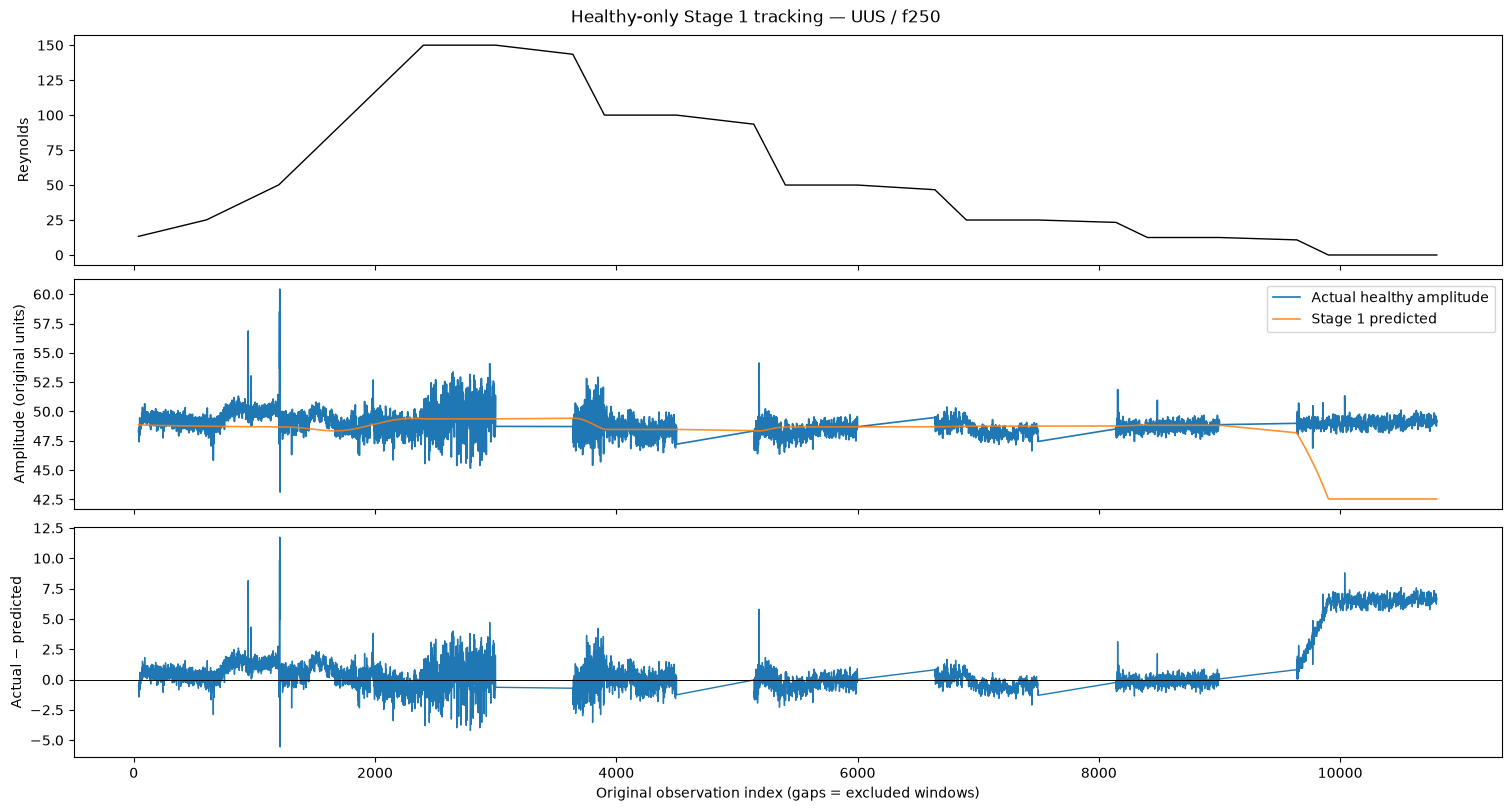

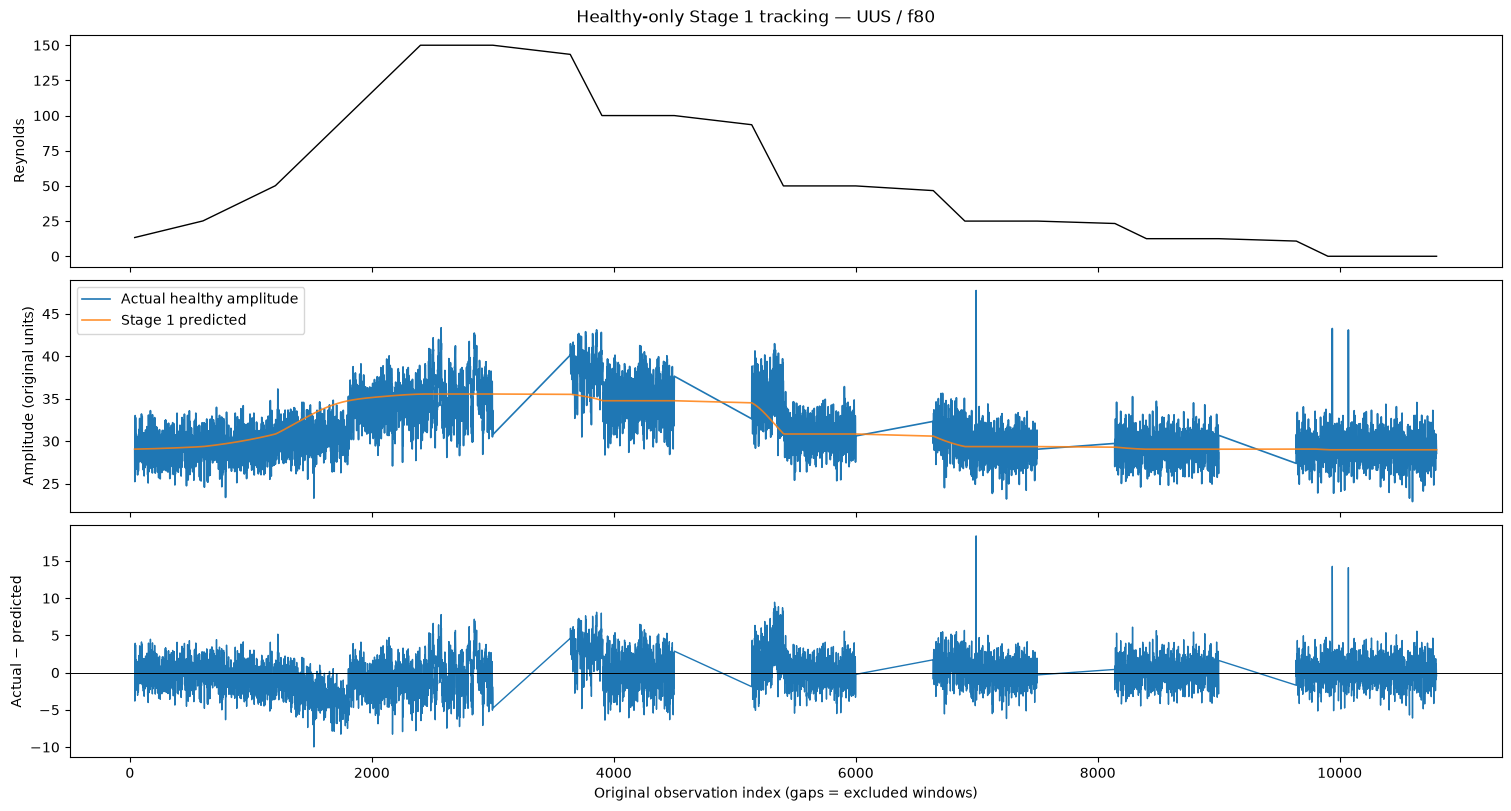

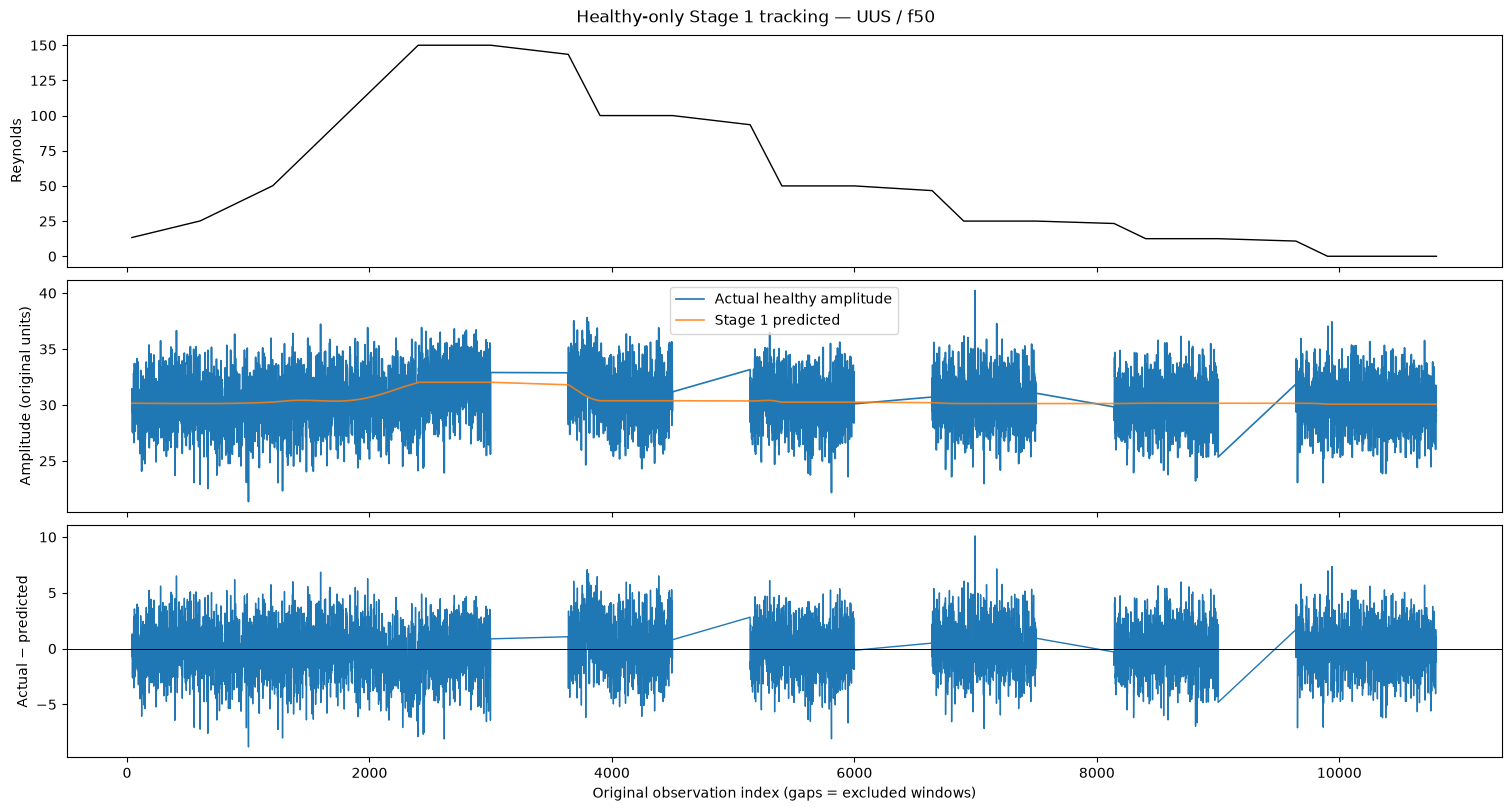

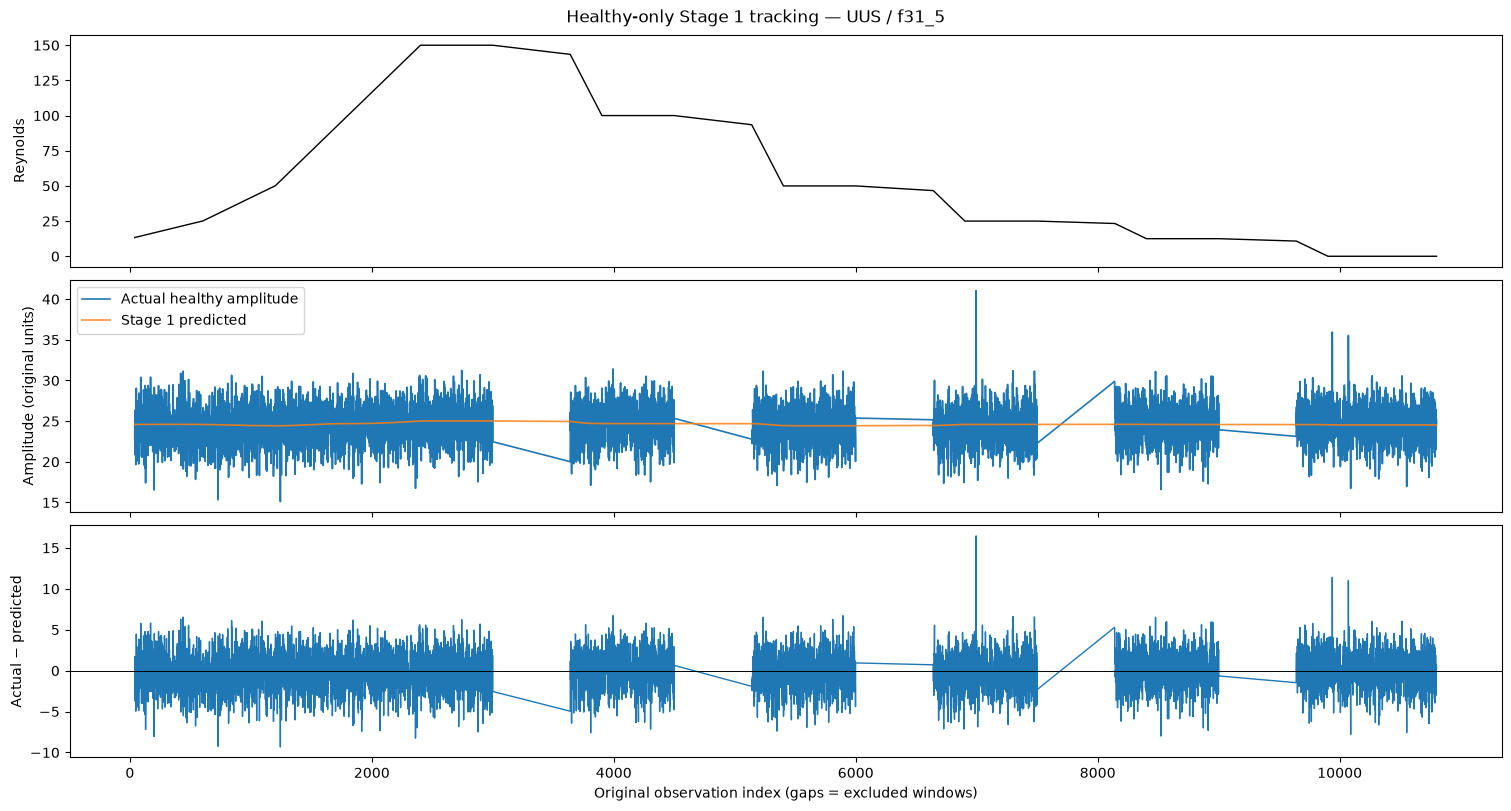

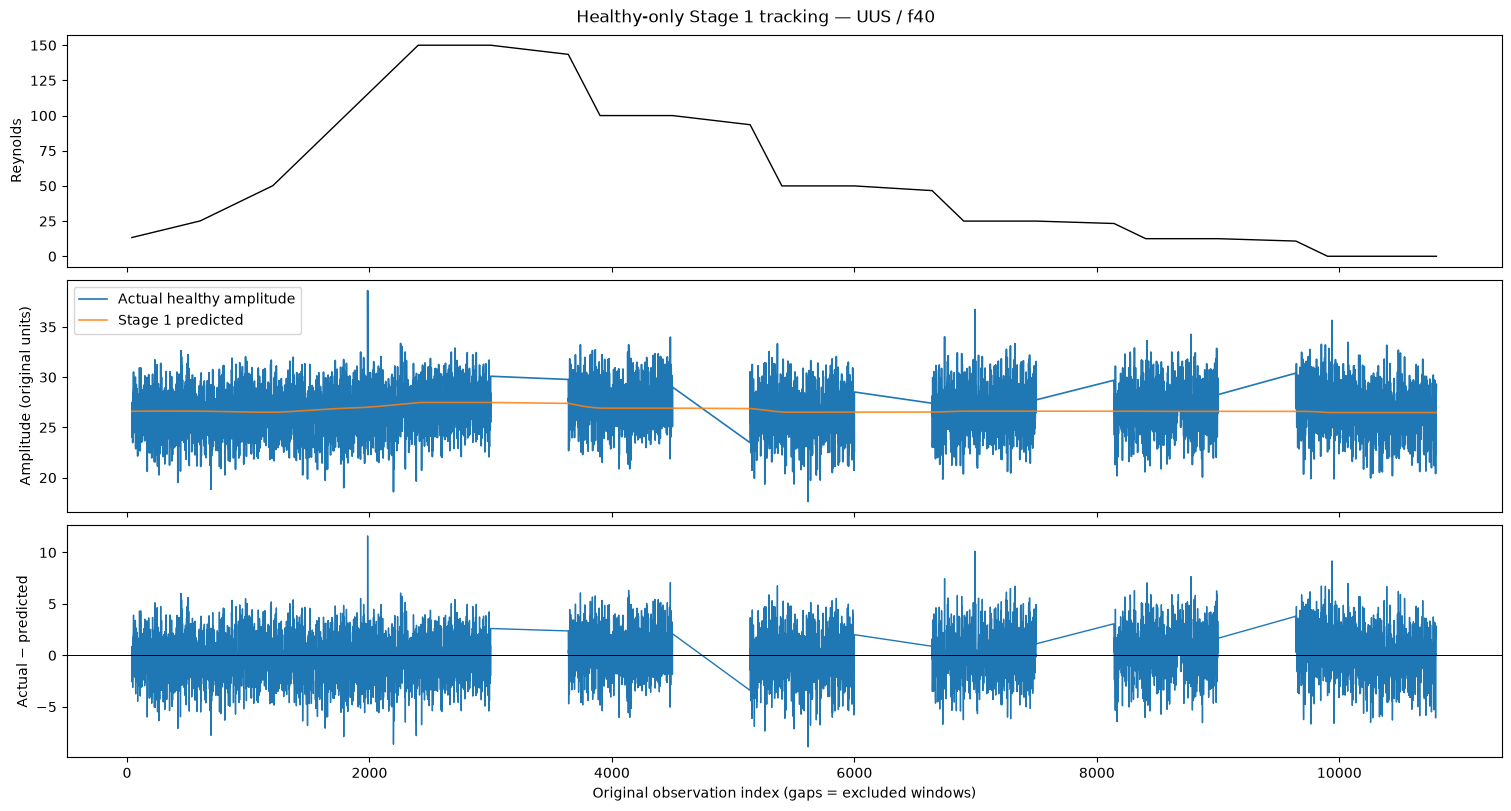

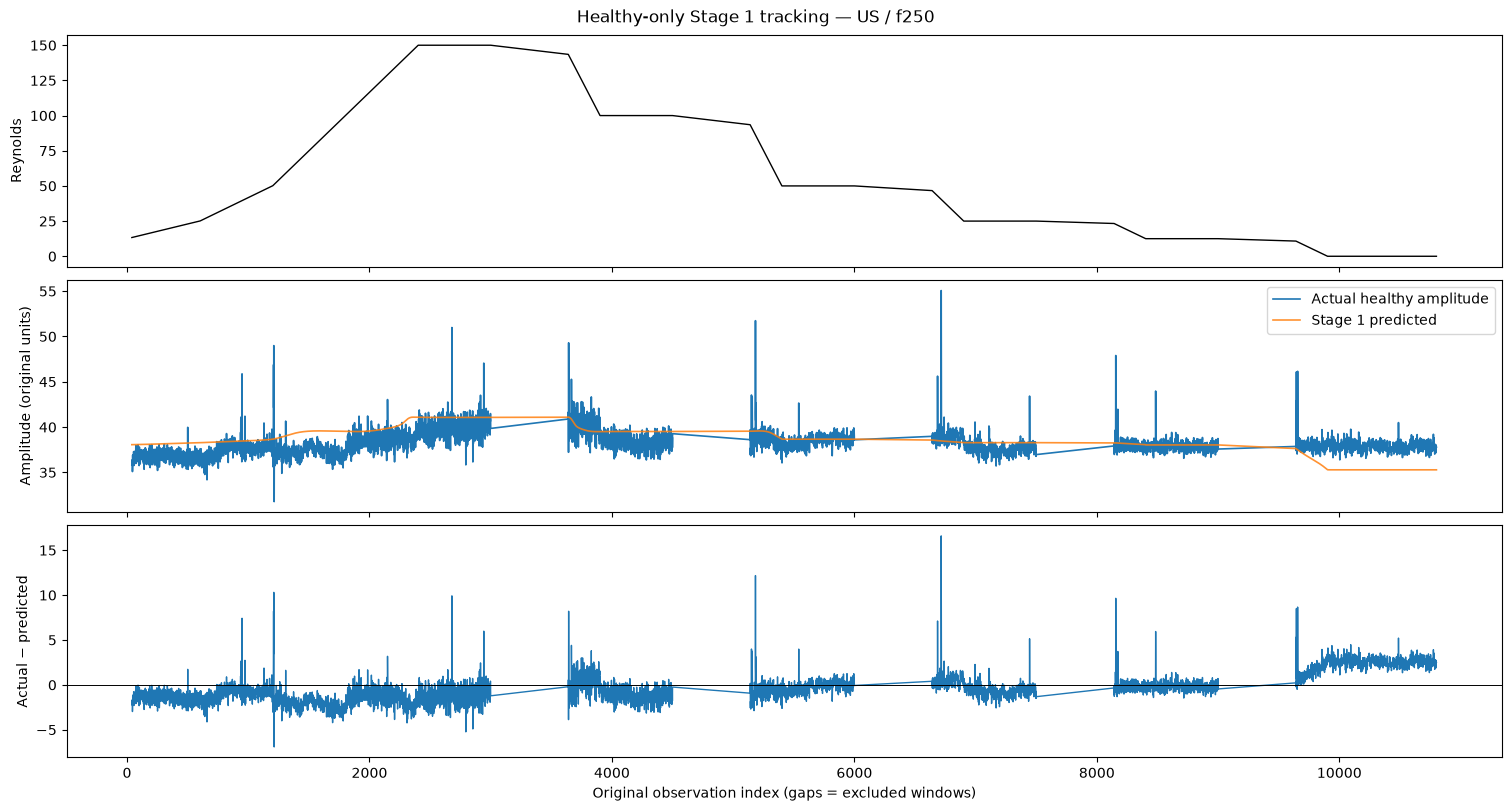

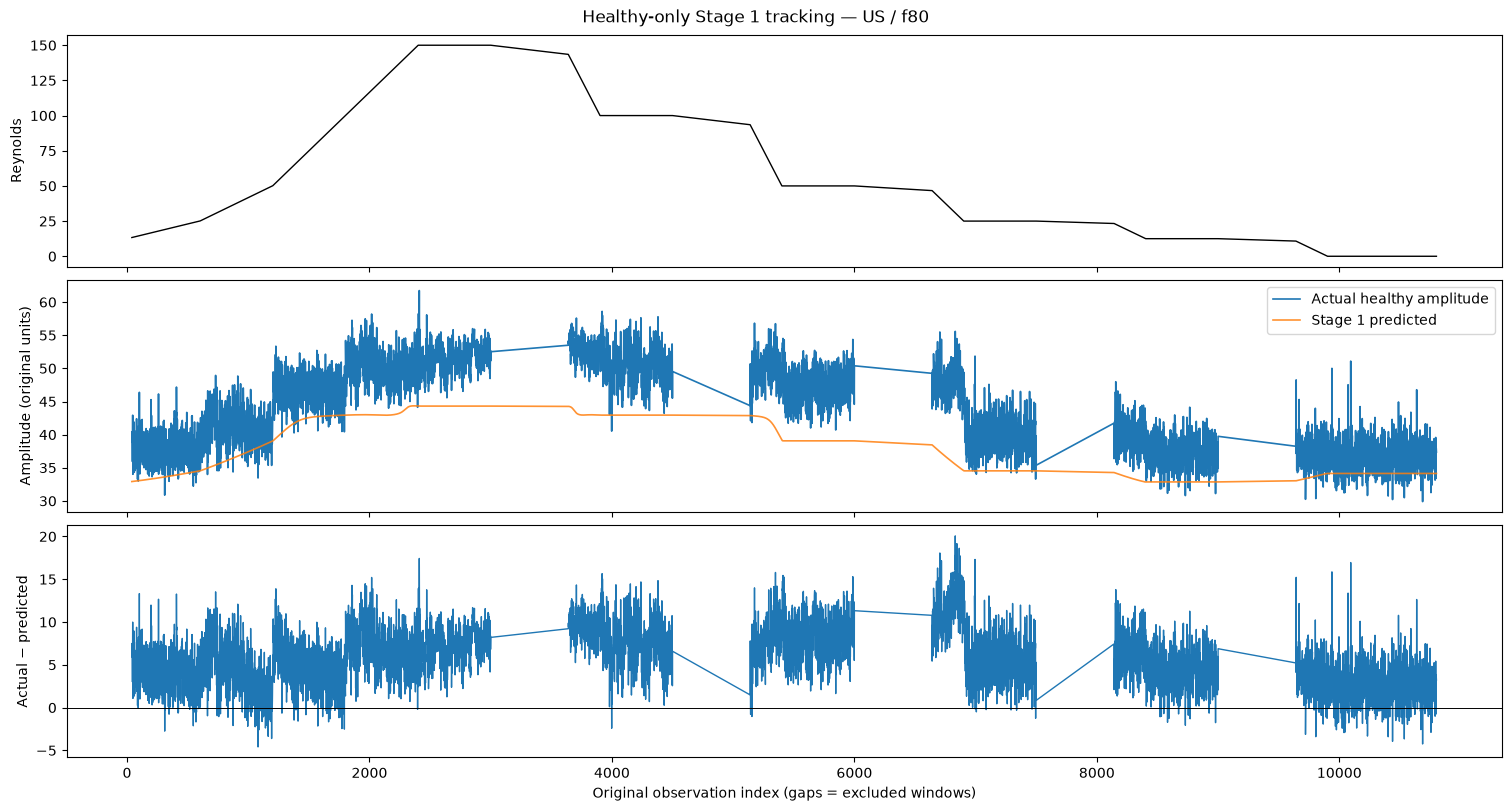

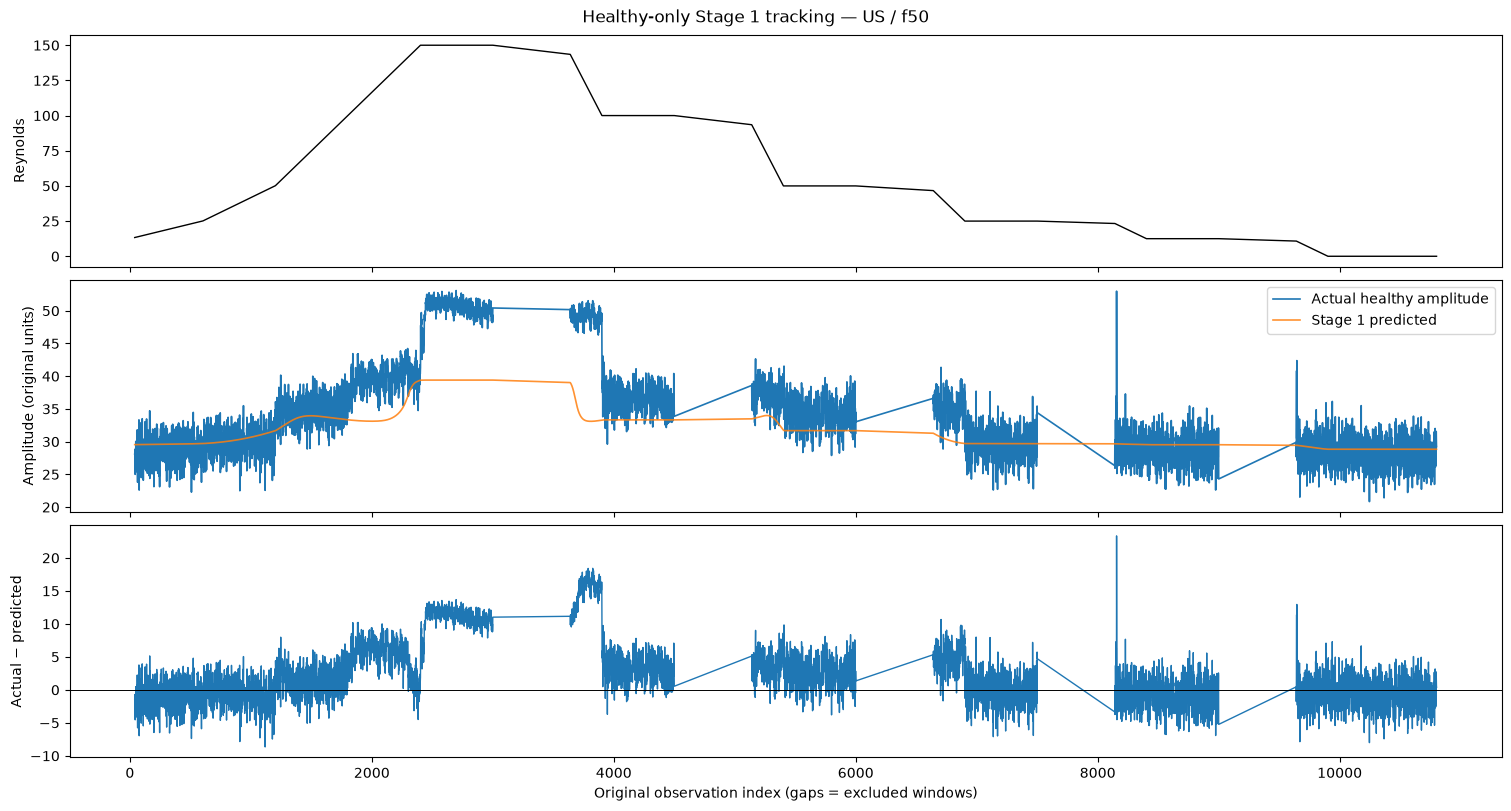

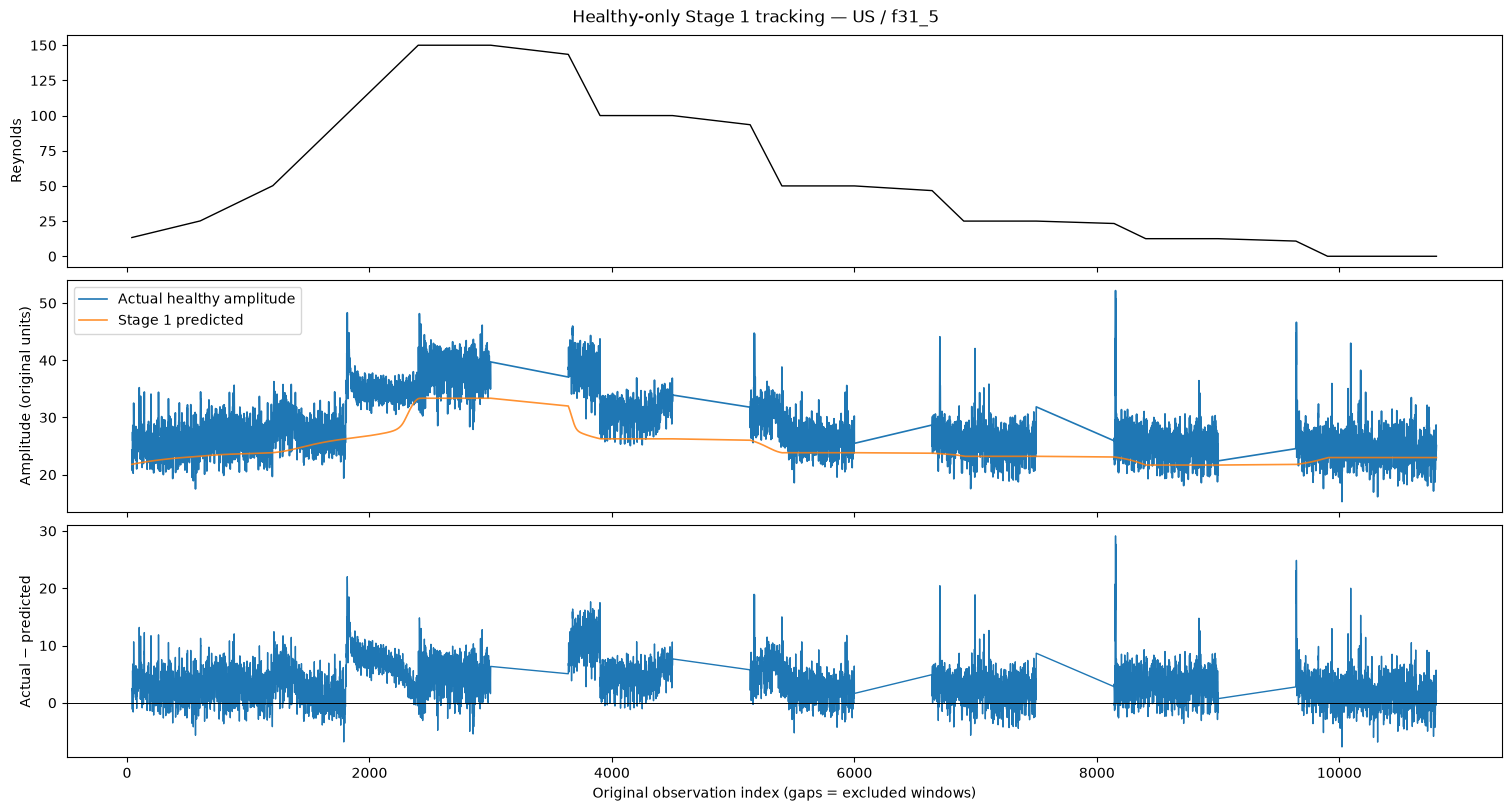

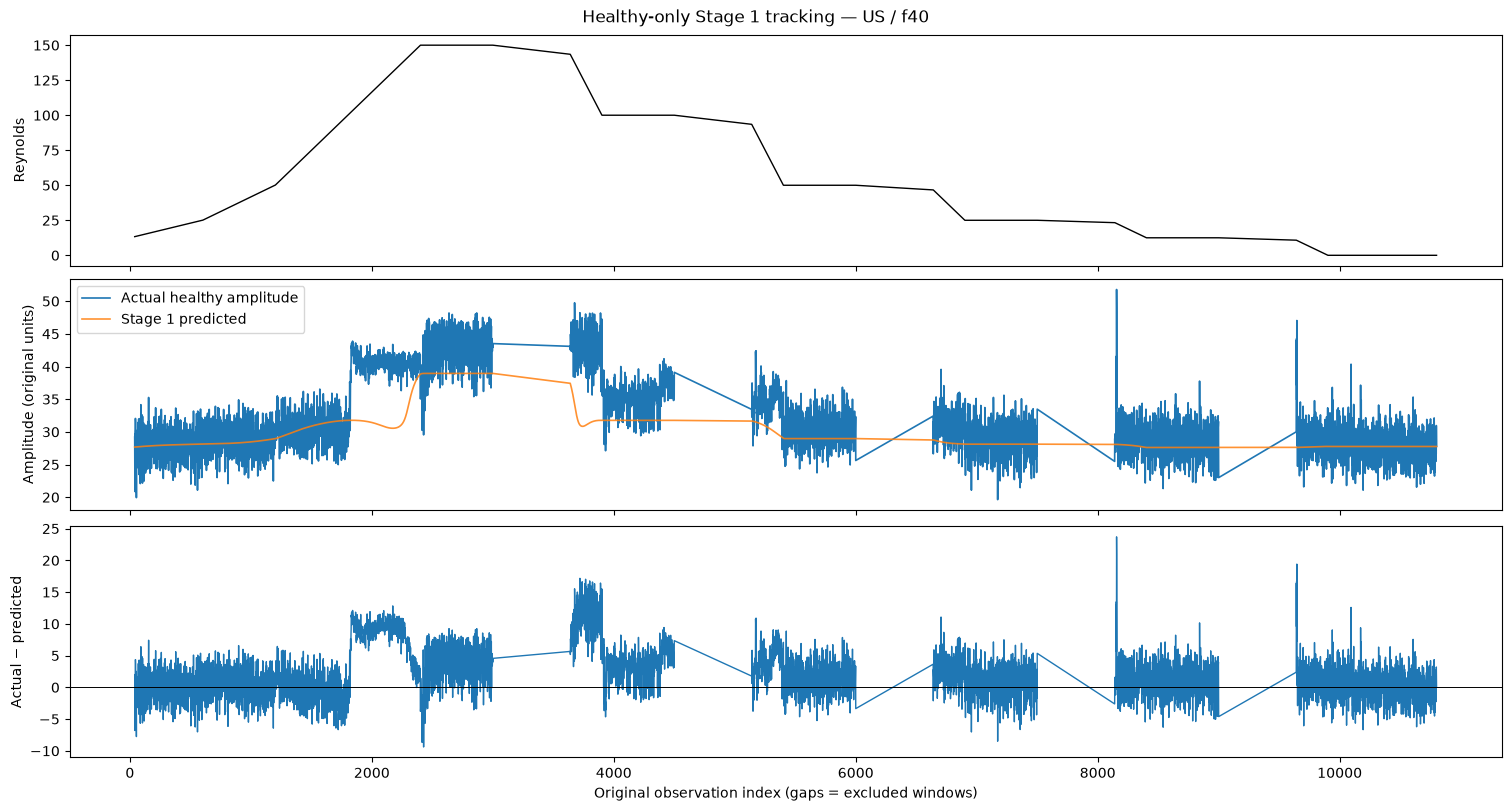

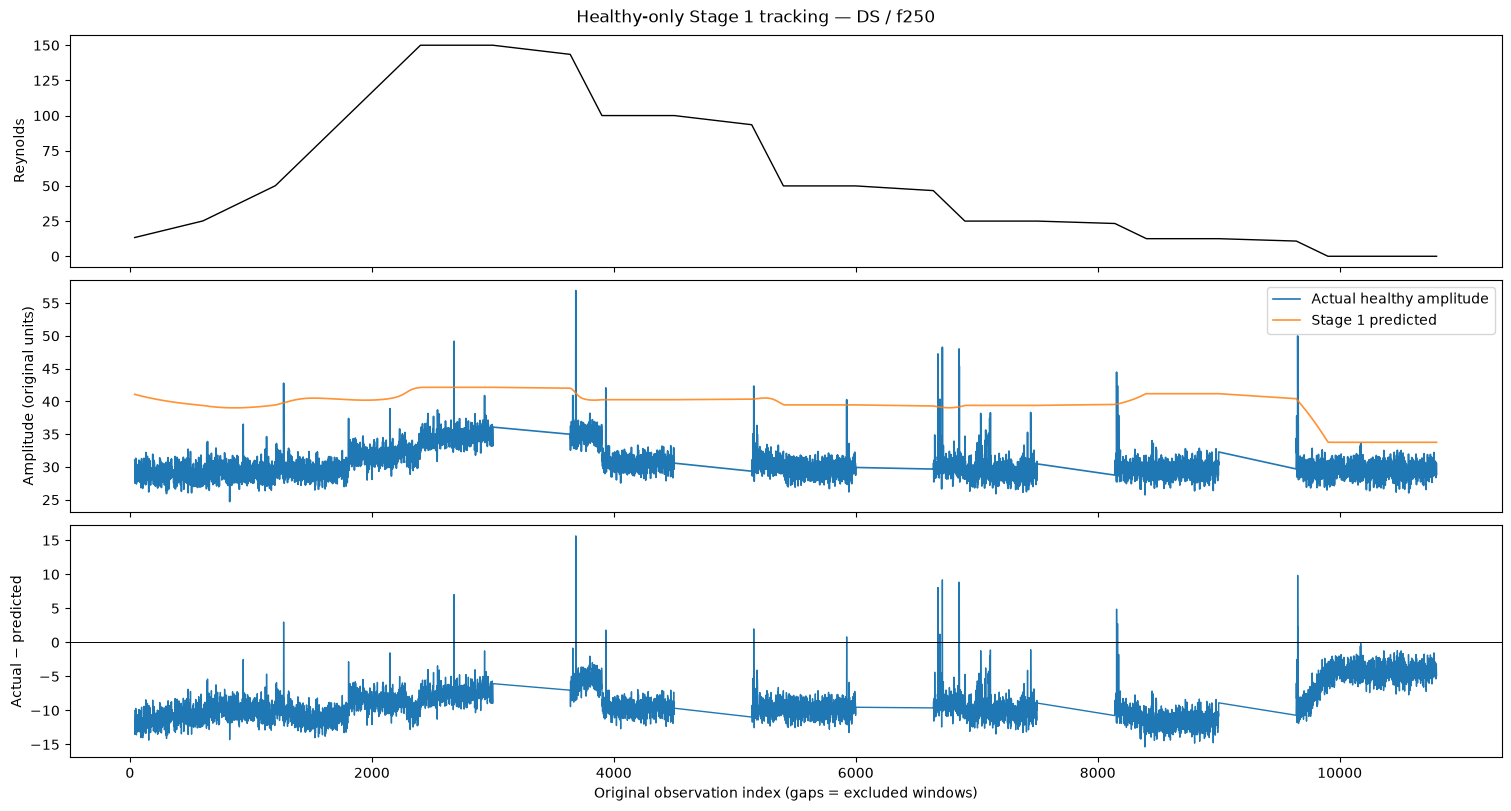

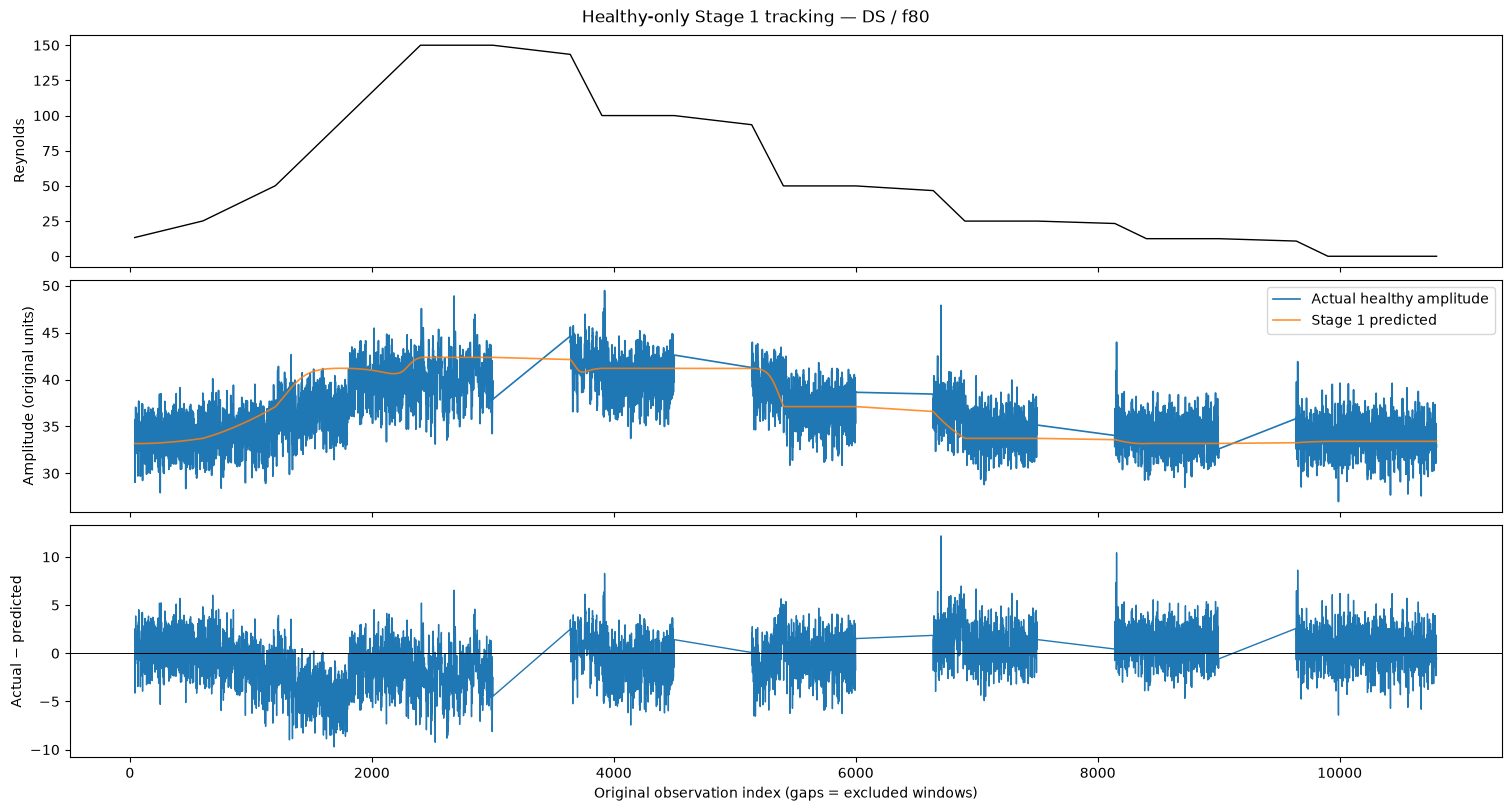

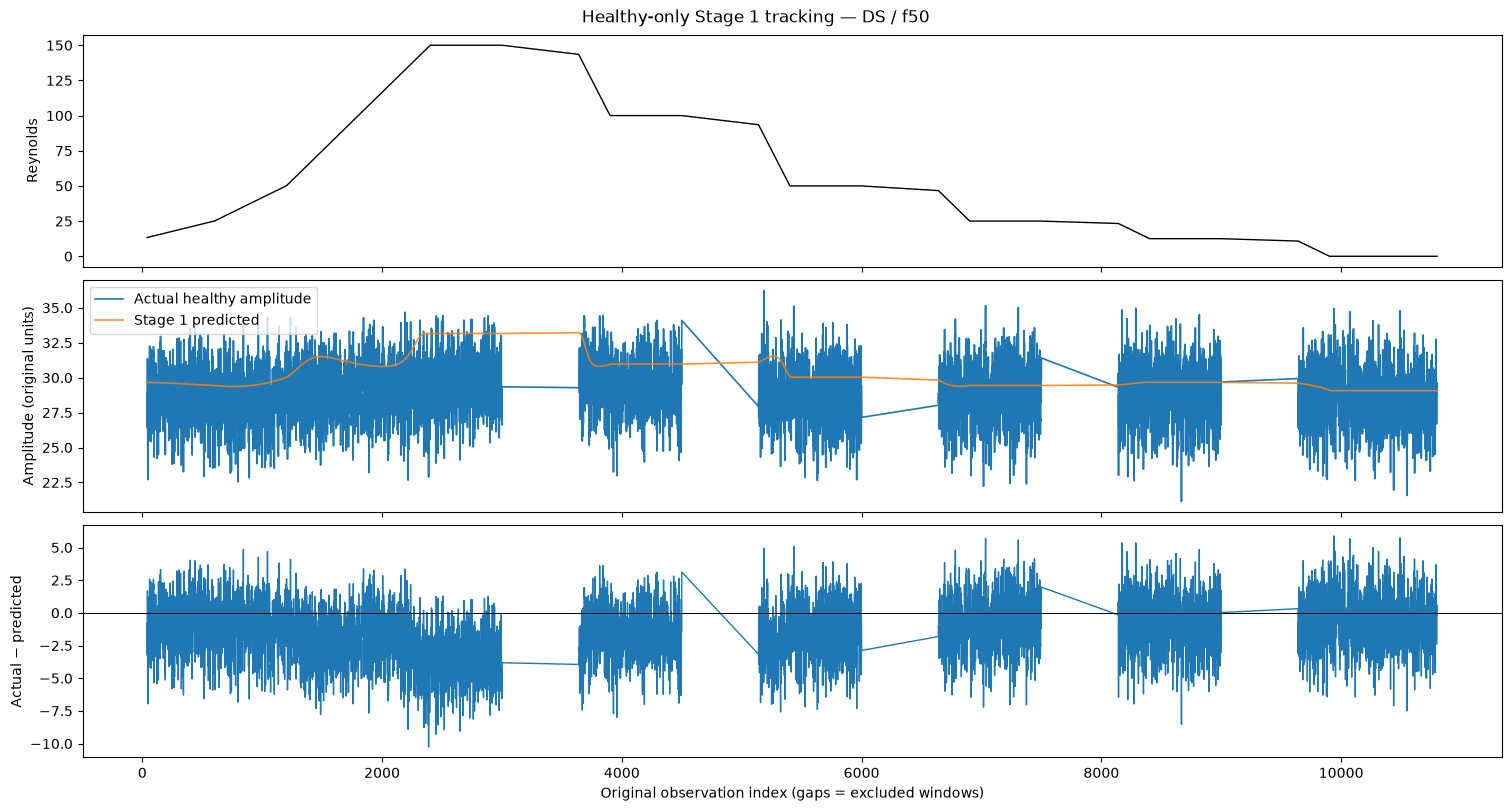

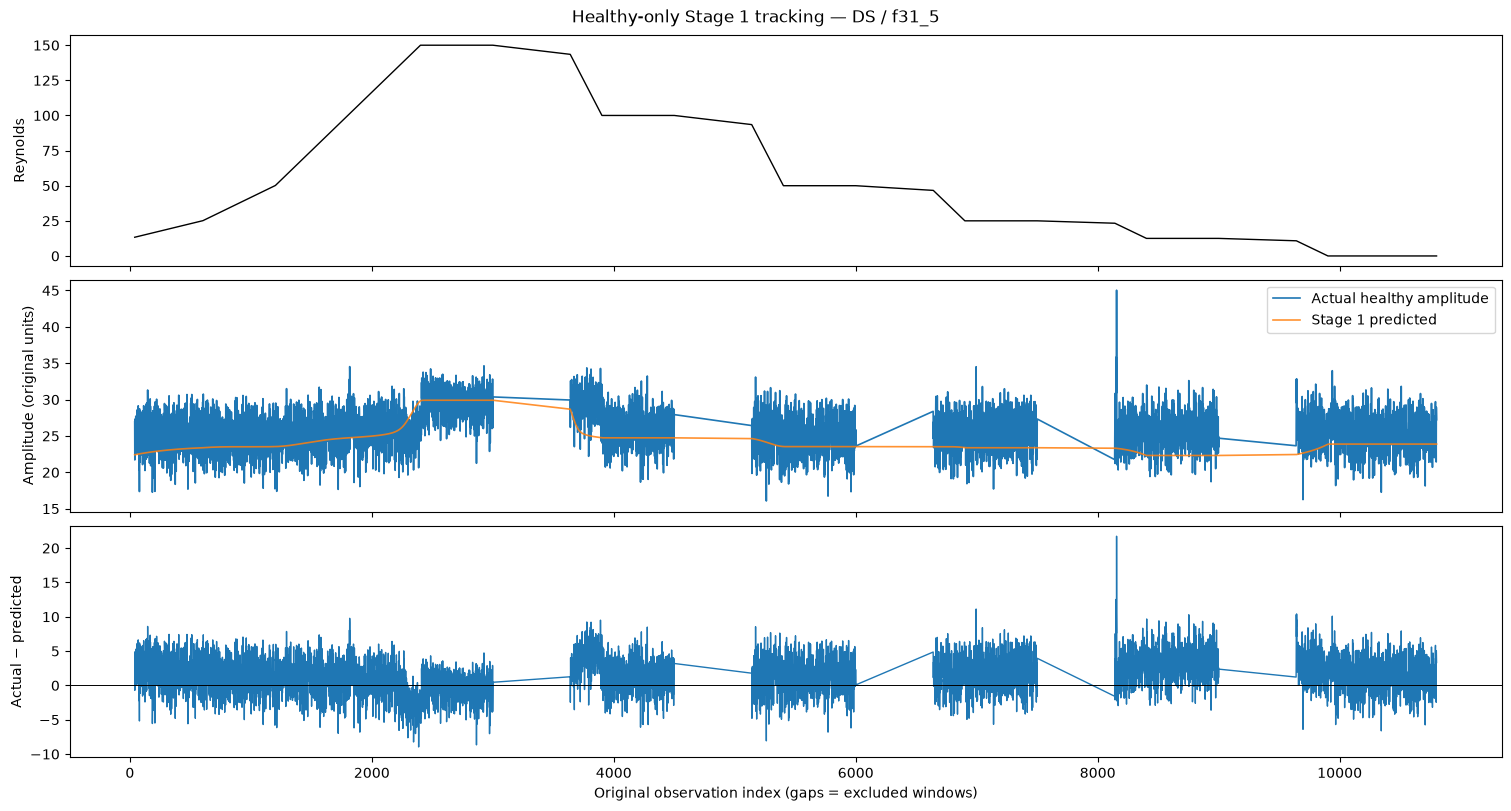

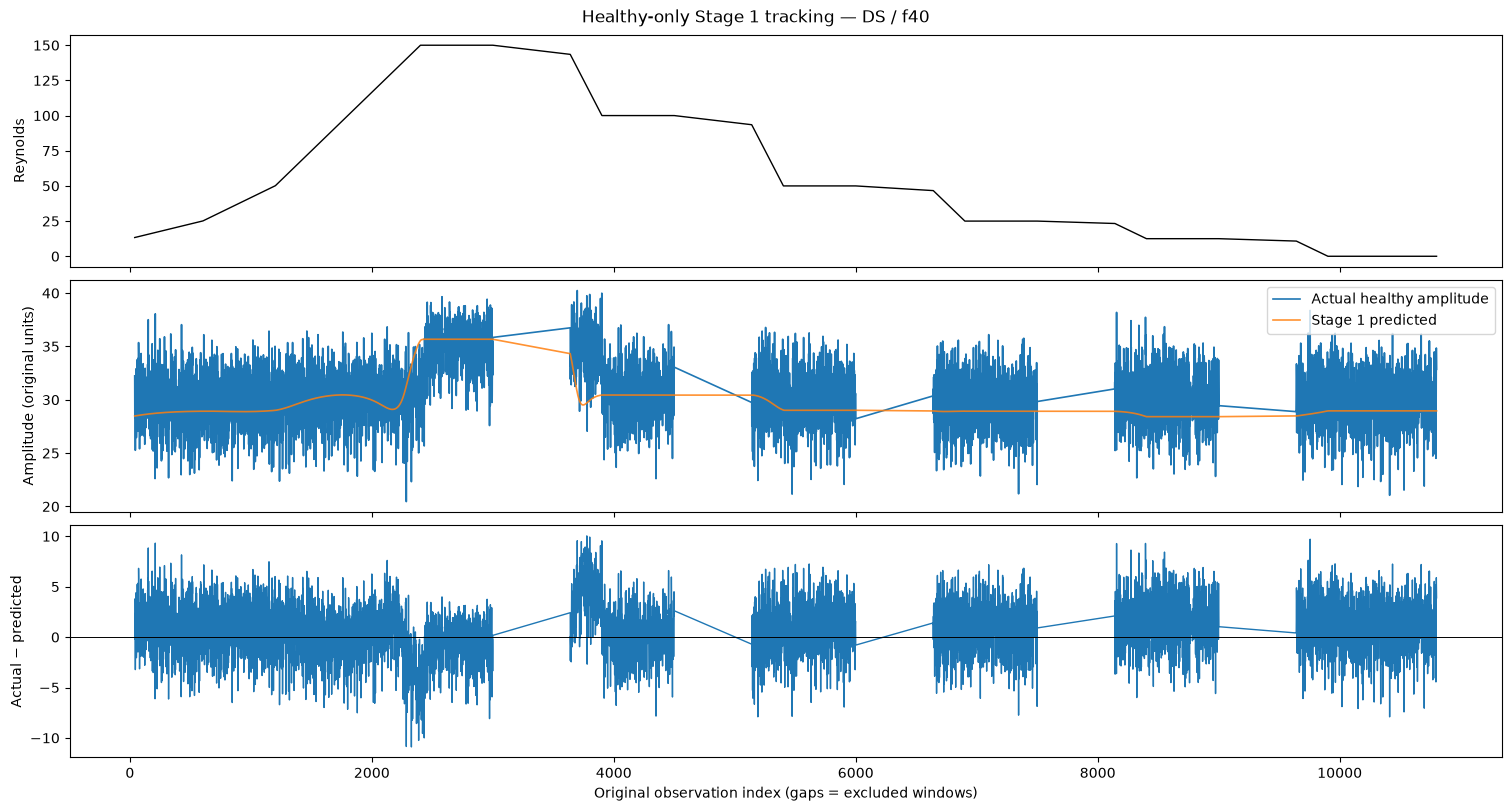

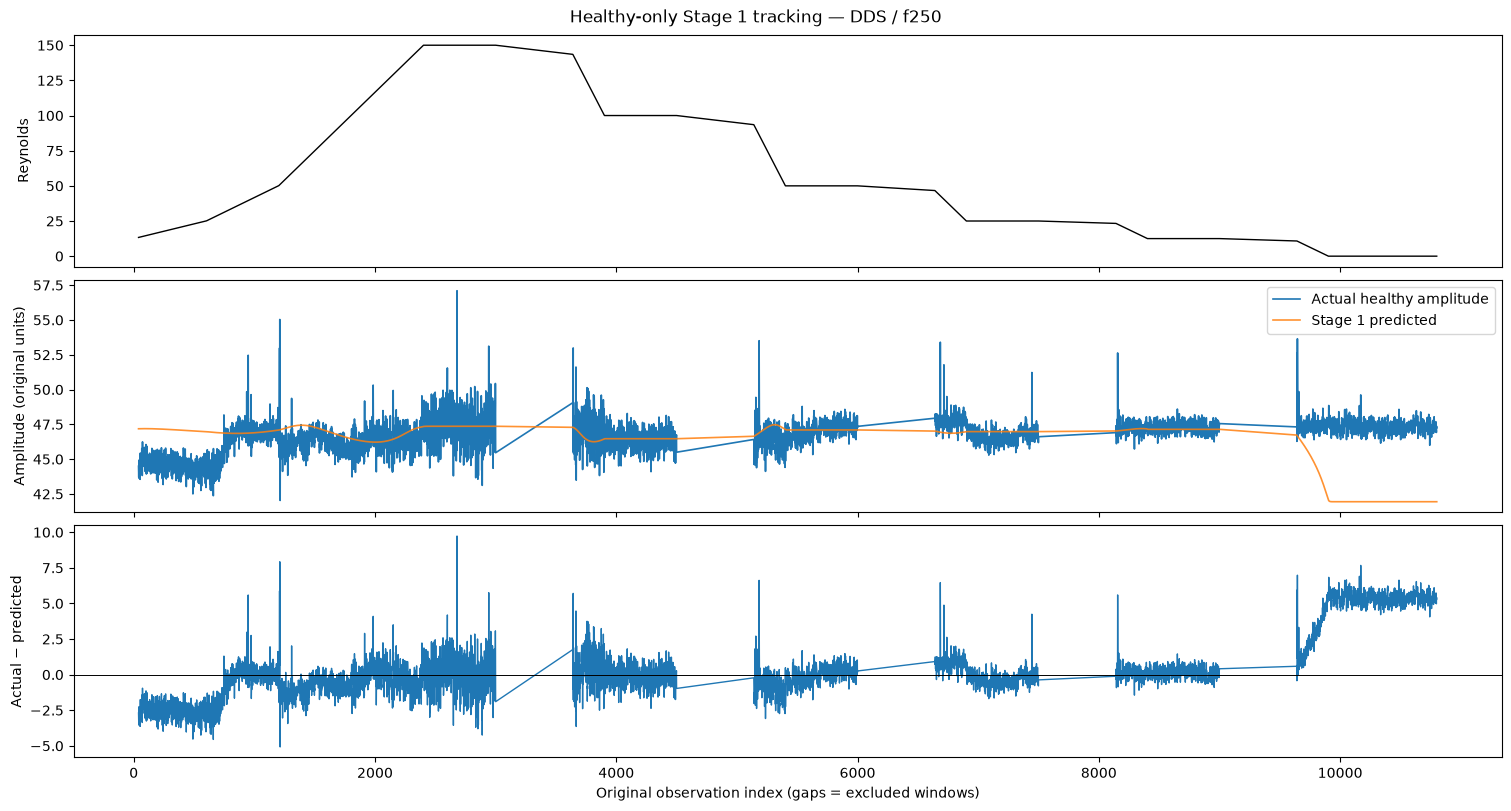

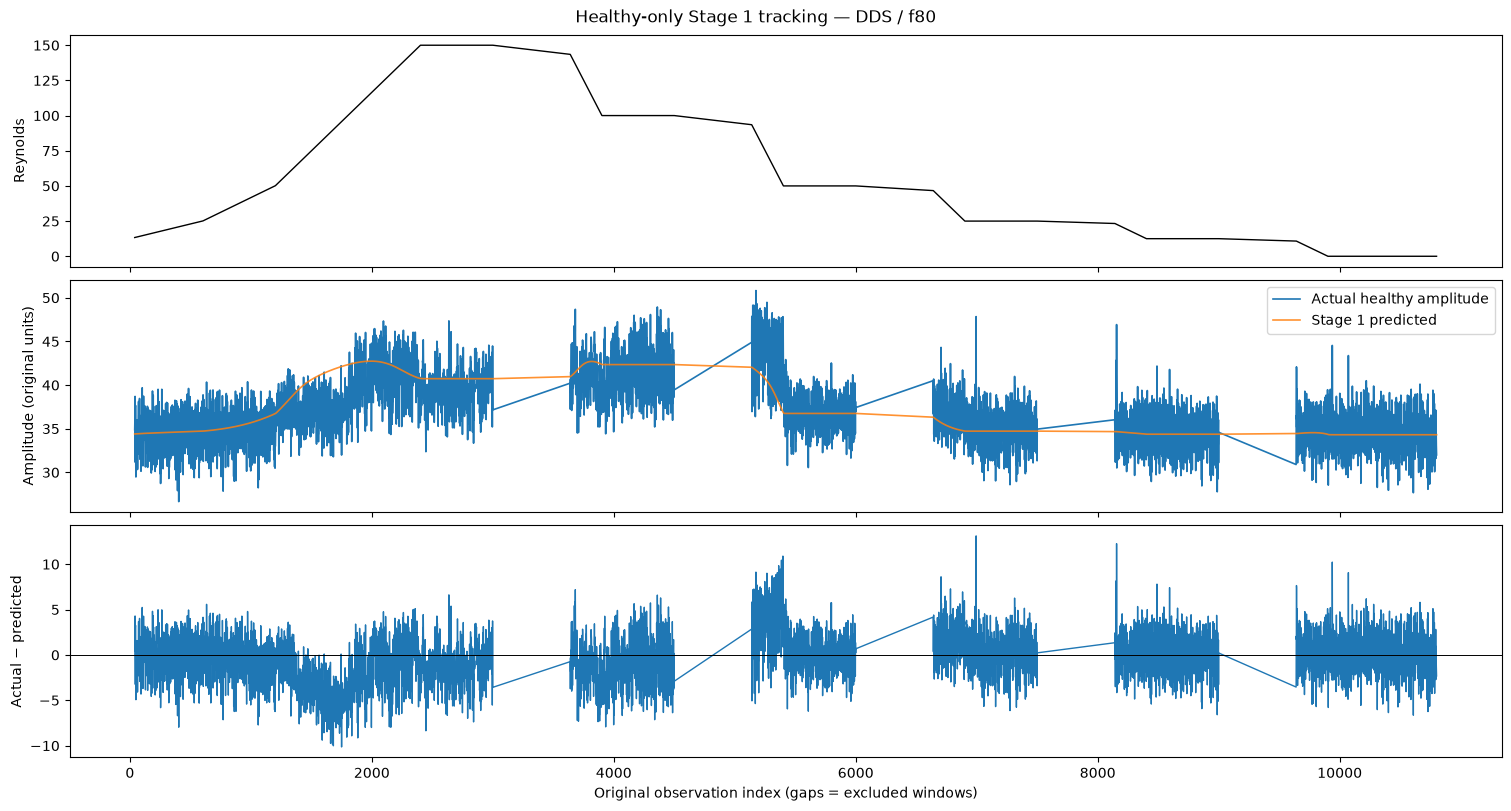

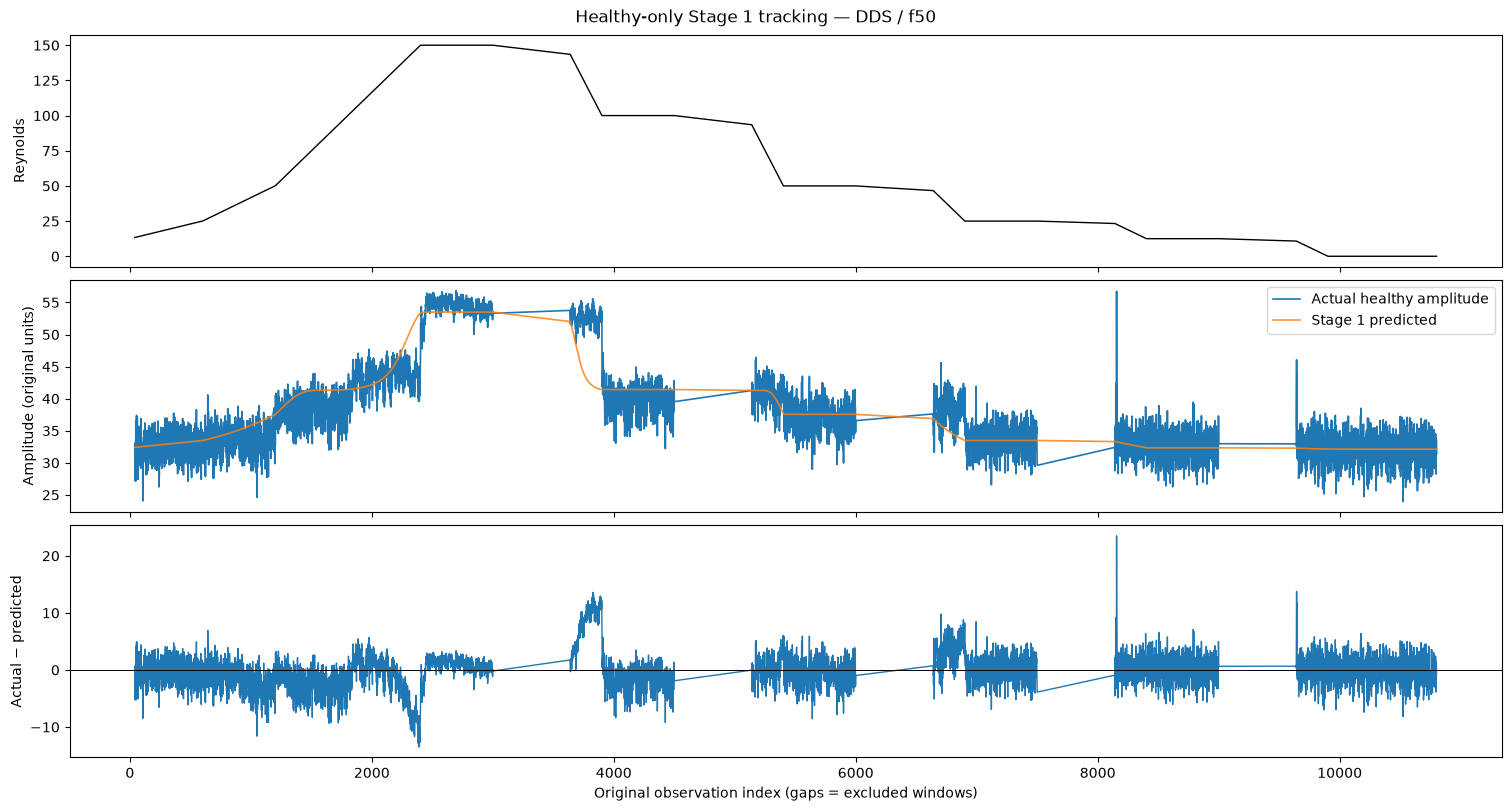

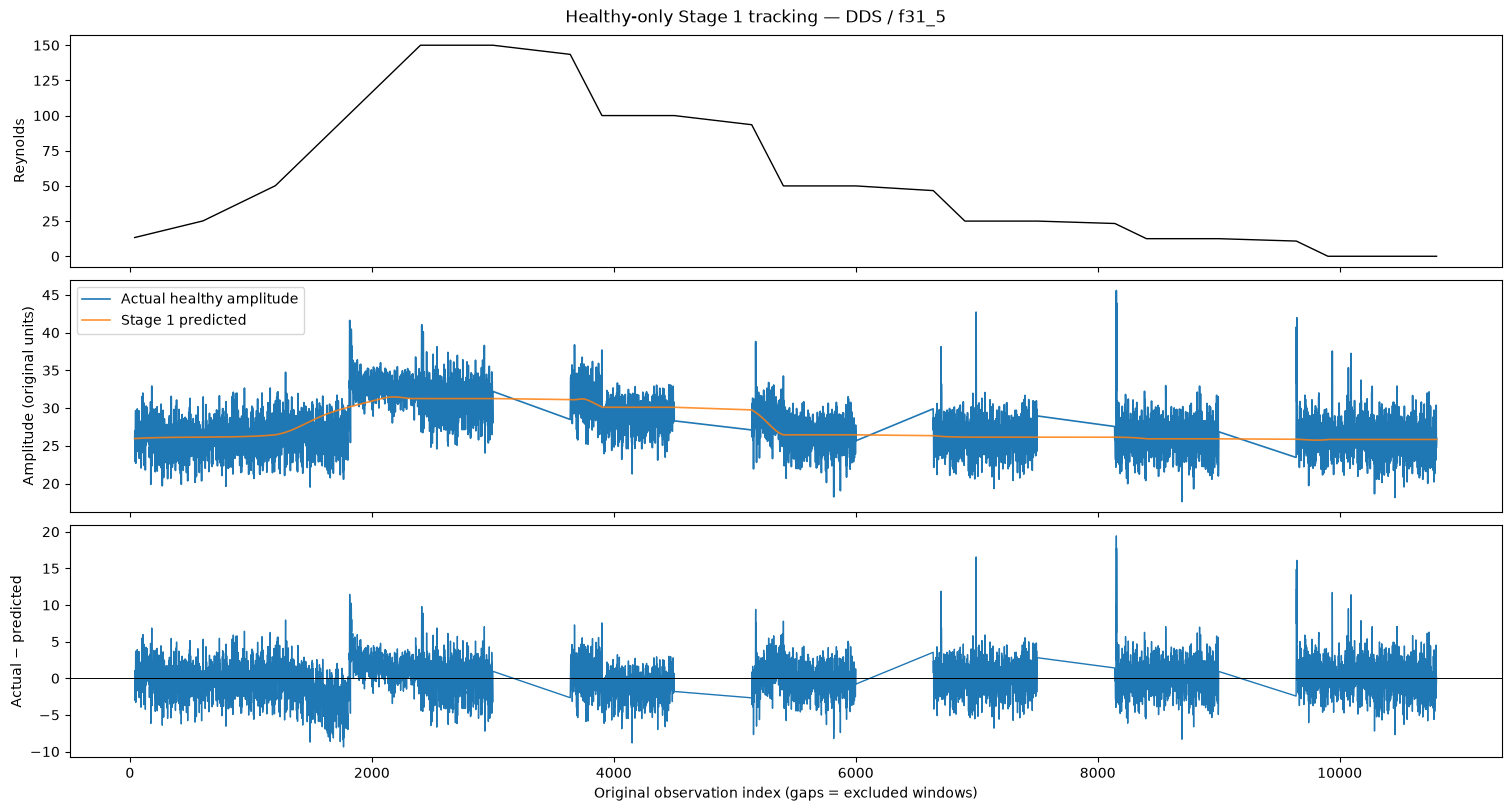

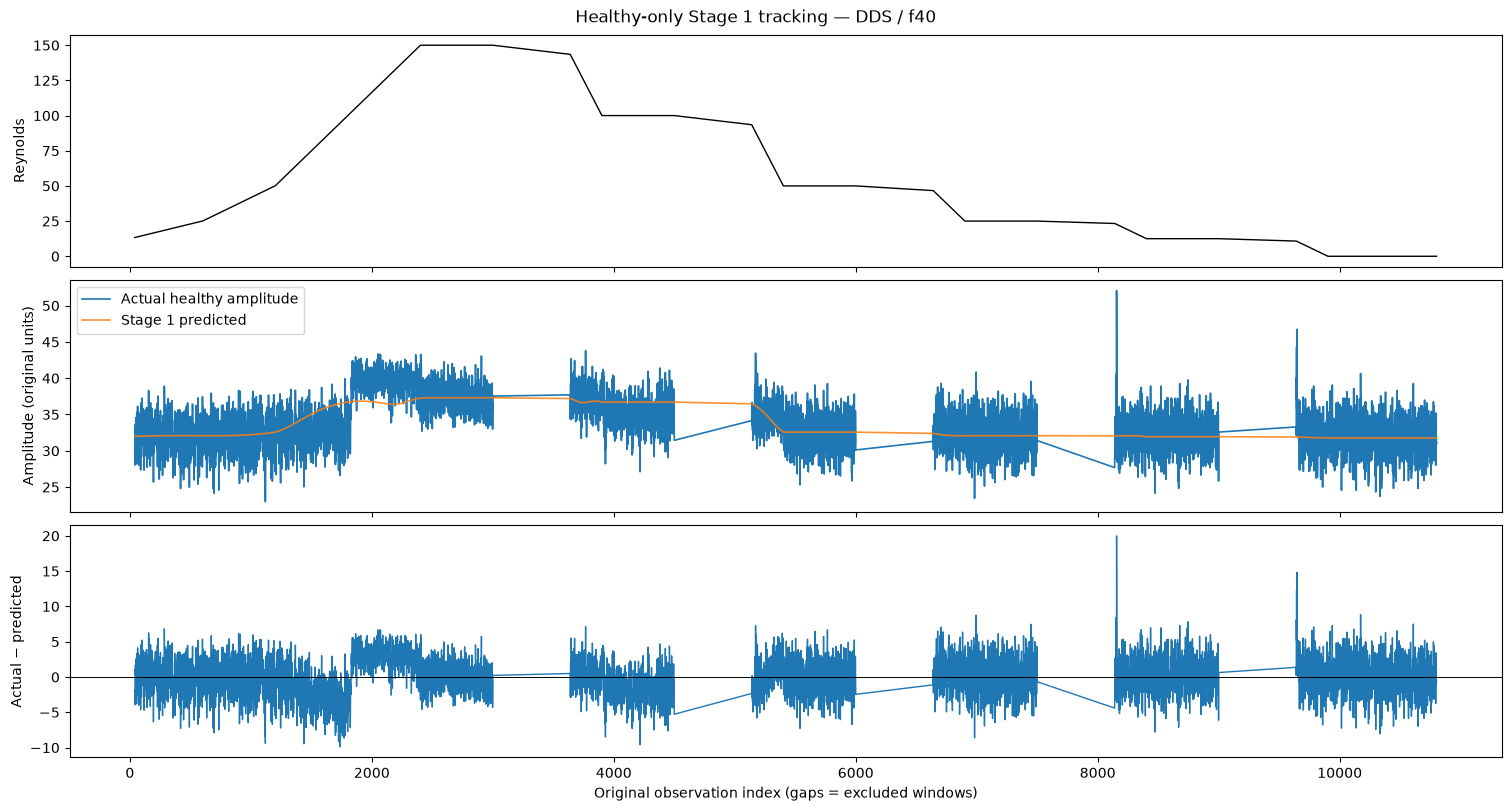

In [19]:
freqs = sample["frequency_labels"]
rows = []
for p, probe in enumerate(PROBE_ORDER):
    for f, freq in enumerate(freqs):
        e = residual[:, p, f]
        rows.append({"probe": probe, "frequency": freq, "RMSE": float(np.sqrt(np.mean(e**2))),
                     "MAE": float(np.mean(np.abs(e))), "bias": float(e.mean()),
                     "corr_actual_predicted": float(np.corrcoef(actual[:,p,f], predicted[:,p,f])[0,1])
                     if np.std(actual[:,p,f]) > 0 and np.std(predicted[:,p,f]) > 0 else np.nan})
frequency_metrics = pd.DataFrame(rows).sort_values("RMSE", ascending=False)
display(frequency_metrics.head(20).round(4))
selected_frequencies = PLOT_FREQUENCIES or frequency_metrics.frequency.drop_duplicates().head(TOP_N_FREQUENCIES).tolist()
print("Frequencies to plot:", selected_frequencies)

def plot_tracking(probe, freq):
    pi, fi = PROBE_ORDER.index(probe), freqs.index(freq)
    x = tracking.observation_index.to_numpy()
    fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
    axes[0].plot(x, tracking.Reynolds, color="black", lw=1)
    axes[0].set_ylabel("Reynolds")
    axes[1].plot(x, actual[:, pi, fi], label="Actual healthy amplitude", lw=1.2)
    axes[1].plot(x, predicted[:, pi, fi], label="Stage 1 predicted", lw=1.2, alpha=.85)
    axes[1].set_ylabel("Amplitude (original units)")
    axes[1].legend(loc="best")
    axes[2].plot(x, residual[:, pi, fi], lw=1)
    axes[2].axhline(0, color="black", lw=.7)
    axes[2].set_ylabel("Actual − predicted")
    axes[2].set_xlabel("Original observation index (gaps = excluded windows)")
    fig.suptitle(f"Healthy-only Stage 1 tracking — {probe} / {freq}")
    path = OUTPUT_DIR / f"tracking_{probe}_{freq}.png"
    fig.savefig(path, dpi=150)
    plt.show()

for probe in PLOT_PROBES:
    for freq in selected_frequencies:
        if freq not in freqs:
            raise ValueError(f"Frequency {freq} not found. Available: {freqs}")
        plot_tracking(probe, freq)

## 4. Stable Reynolds vs transitions: Stage 1 accuracy

The transition flag is defined by a change between consecutive raw Reynolds observations. Note: this is a **single-step** definition; Stage 1 may have lingering errors after a transition even if the endpoint is stable. The second flag detects **any Reynolds change within the full 40-step input window**. This is a more relevant comparison for the LSTM.


Grouping: is_transition


,n,mean_RMSE,median_RMSE,mean_relative_RMSE,mean_MAE
is_transition,,,,,
False,3895,2.2715,2.1913,0.0907,1.5353
True,3672,2.5322,2.3492,0.1001,1.7181



Grouping: transition_within_window


,n,mean_RMSE,median_RMSE,mean_relative_RMSE,mean_MAE
transition_within_window,,,,,
False,3661,2.2526,2.1868,0.0901,1.5218
True,3906,2.5343,2.3488,0.1001,1.7198


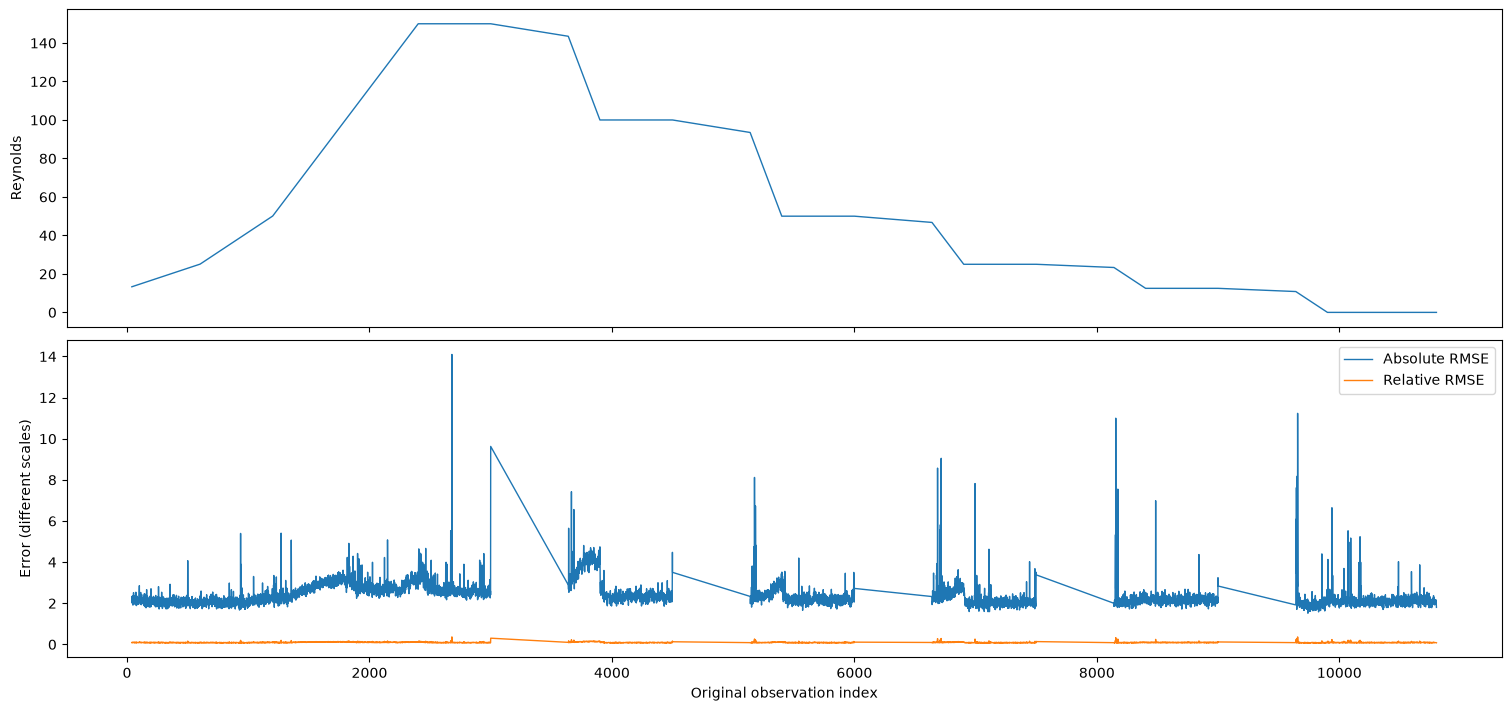

In [20]:
re_all = sample["Re"].numpy() * 150
change = np.r_[False, np.abs(np.diff(re_all)) > TRANSITION_THRESHOLD]
window_change = np.convolve(change.astype(int), np.ones(WINDOW_SIZE, dtype=int), mode="valid") > 0
tracking["transition_within_window"] = window_change[window_ids]
for col in ["is_transition", "transition_within_window"]:
    summary = tracking.groupby(col, dropna=False).agg(
        n=("endpoint_RMSE", "size"), mean_RMSE=("endpoint_RMSE", "mean"),
        median_RMSE=("endpoint_RMSE", "median"),
        mean_relative_RMSE=("relative_RMSE", "mean"),
        mean_MAE=("endpoint_MAE", "mean"))
    print("\nGrouping:", col)
    display(summary.round(4))

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True, constrained_layout=True)
x = tracking.observation_index
axes[0].plot(x, tracking.Reynolds, lw=1)
axes[0].set_ylabel("Reynolds")
axes[1].plot(x, tracking.endpoint_RMSE, label="Absolute RMSE", lw=1)
axes[1].plot(x, tracking.relative_RMSE, label="Relative RMSE", lw=1)
axes[1].legend()
axes[1].set_ylabel("Error (different scales)")
axes[1].set_xlabel("Original observation index")
fig.savefig(OUTPUT_DIR / "reynolds_vs_stage1_error.png", dpi=150)
plt.show()

## 5. Error by Reynolds operating regime

Absolute error may rise with Reynolds simply because acoustic amplitudes rise. **Relative RMSE** divides endpoint RMSE by the RMS of the observed spectrum at that endpoint, so inspect both. This normalization is unstable if actual amplitudes approach zero; such cases are reported as missing.

,n,mean_RMSE,median_RMSE,mean_relative_RMSE,transition_fraction
Reynolds_bin,,,,,
<10,1140,2.1011,2.0648,0.0896,0.2447
10–25,2045,2.1484,2.0874,0.0909,0.4523
25–50,1461,2.2402,2.1648,0.0921,0.6167
50–75,450,2.4980,2.4486,0.0989,1.0000
75–100,1011,2.5594,2.4301,0.0992,0.4461
100–125,450,3.2743,2.9828,0.1165,1.0000
125–150,1010,2.8704,2.7144,0.1000,0.4455


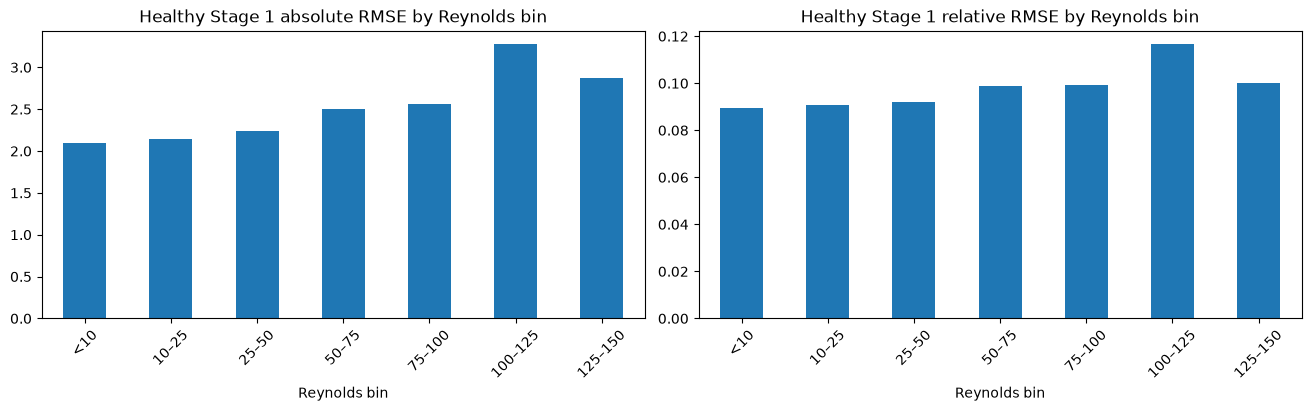

In [21]:
bins = [-np.inf,10,25,50,75,100,125,150,np.inf]
labels = ["<10","10–25","25–50","50–75","75–100","100–125","125–150",">150"]
tracking["Reynolds_bin"] = pd.cut(tracking.Reynolds, bins=bins, labels=labels, include_lowest=True)
by_re = tracking.groupby("Reynolds_bin", observed=True).agg(
    n=("endpoint_RMSE","size"), mean_RMSE=("endpoint_RMSE","mean"),
    median_RMSE=("endpoint_RMSE","median"), mean_relative_RMSE=("relative_RMSE","mean"),
    transition_fraction=("transition_within_window","mean"))
display(by_re.round(4))
fig, axes = plt.subplots(1,2,figsize=(13,4), constrained_layout=True)
by_re.mean_RMSE.plot.bar(ax=axes[0], title="Healthy Stage 1 absolute RMSE by Reynolds bin")
by_re.mean_relative_RMSE.plot.bar(ax=axes[1], title="Healthy Stage 1 relative RMSE by Reynolds bin")
for ax in axes: ax.set_xlabel("Reynolds bin"); ax.tick_params(axis="x",rotation=45)
fig.savefig(OUTPUT_DIR / "error_by_reynolds.png", dpi=150)
plt.show()

## 6. Probe × frequency error map and transition-specific bias

This highlights frequencies where Stage 1 makes large errors on healthy data and where errors are larger for windows containing Reynolds changes. **Bias** is signed (actual − predicted): a consistent nonzero bias can indicate under- or over-prediction even if RMSE looks moderate.

,probe,frequency,overall_RMSE,overall_bias,transition_RMSE,stable_RMSE,transition_bias,stable_bias,transition_minus_stable_RMSE
29,US,f40,4.4693,2.2600,5.3134,3.3413,2.7430,1.7447,1.9722
28,US,f31_5,5.1421,3.7652,5.8567,4.2491,4.3944,3.0939,1.6076
84,DDS,f50,3.1612,-0.1692,3.8295,2.2381,-0.1127,-0.2295,1.5914
35,US,f160,2.9358,0.7998,3.5344,2.1181,0.8247,0.7733,1.4163
85,DDS,f63,2.5966,-0.2737,3.1738,1.7857,-0.6065,0.0814,1.3881
92,DDS,f315,2.6839,0.4346,3.2448,1.9120,0.2010,0.6838,1.3328
62,DS,f160,3.6495,-2.5035,4.1979,2.9543,-2.7700,-2.2193,1.2435
38,US,f315,3.1222,-1.3582,3.6327,2.4634,-1.7502,-0.9399,1.1693
33,US,f100,4.0176,2.7013,4.4650,3.4773,3.0450,2.3346,0.9877
8,UUS,f160,1.9425,-0.2043,2.3325,1.4124,-0.3052,-0.0967,0.9201


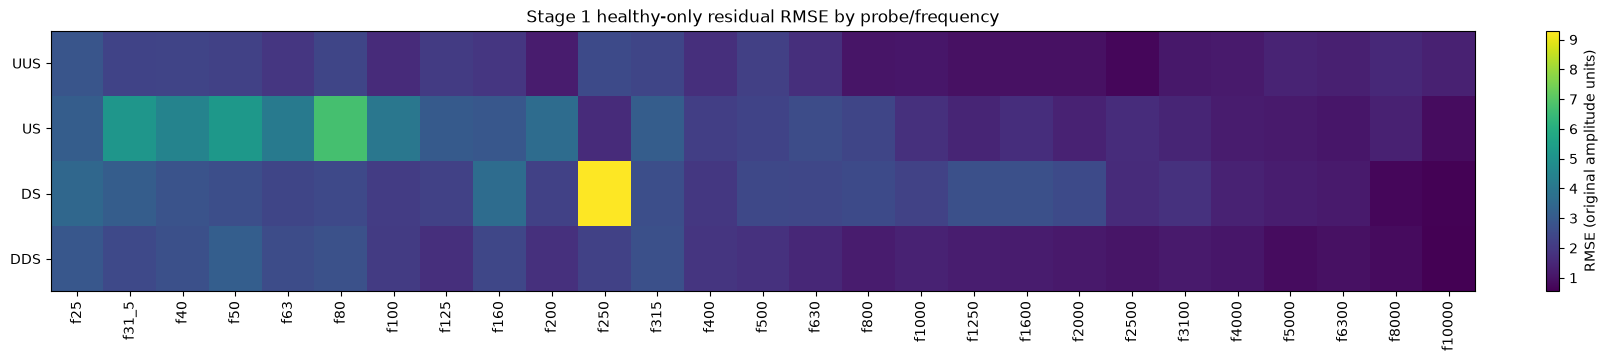

In [22]:
transition_mask = tracking.transition_within_window.to_numpy()
rows = []
for pi, probe in enumerate(PROBE_ORDER):
    for fi, freq in enumerate(freqs):
        e = residual[:,pi,fi]
        rows.append({"probe":probe, "frequency":freq,
                     "overall_RMSE":float(np.sqrt(np.mean(e**2))),
                     "overall_bias":float(e.mean()),
                     "transition_RMSE":float(np.sqrt(np.mean(e[transition_mask]**2))) if transition_mask.any() else np.nan,
                     "stable_RMSE":float(np.sqrt(np.mean(e[~transition_mask]**2))) if (~transition_mask).any() else np.nan,
                     "transition_bias":float(e[transition_mask].mean()) if transition_mask.any() else np.nan,
                     "stable_bias":float(e[~transition_mask].mean()) if (~transition_mask).any() else np.nan})
probe_frequency = pd.DataFrame(rows)
probe_frequency["transition_minus_stable_RMSE"] = probe_frequency.transition_RMSE - probe_frequency.stable_RMSE
display(probe_frequency.sort_values("transition_minus_stable_RMSE",ascending=False).head(20).round(4))
heat = probe_frequency.pivot(index="probe", columns="frequency", values="overall_RMSE").reindex(index=PROBE_ORDER,columns=freqs)
fig, ax = plt.subplots(figsize=(16,3.5),constrained_layout=True)
im = ax.imshow(heat.to_numpy(),aspect="auto")
ax.set_yticks(range(len(PROBE_ORDER)),PROBE_ORDER)
ax.set_xticks(range(len(freqs)),freqs,rotation=90)
fig.colorbar(im,ax=ax,label="RMSE (original amplitude units)")
ax.set_title("Stage 1 healthy-only residual RMSE by probe/frequency")
fig.savefig(OUTPUT_DIR / "probe_frequency_rmse_heatmap.png",dpi=150)
plt.show()

## 7. Check for delayed tracking after Reynolds changes

For each Reynolds-change event, inspect signed residuals around the transition. The figure below plots **average endpoint RMSE** by the number of observations since the most recent Reynolds change (not a causal estimate). The result is informative only if the data contain enough healthy windows at each delay. We also report counts. We do **not** estimate lag by correlating amplitude with Reynolds because their relationship may be nonlinear and confounded by operating regime.

,n,mean_RMSE,median_RMSE,mean_relative_RMSE
steps_since_Re_change,,,,
0.0,3672,2.5322,2.3492,0.1001
1.0,6,2.9493,2.7539,0.1133
2.0,6,2.6140,2.5692,0.1023
3.0,6,2.5740,2.5190,0.1004
4.0,6,2.7591,2.4506,0.1063
5.0,6,3.1537,2.9042,0.1200
6.0,6,2.9012,2.5836,0.1116
7.0,6,2.4398,2.4908,0.0954
8.0,6,2.5680,2.2988,0.0996


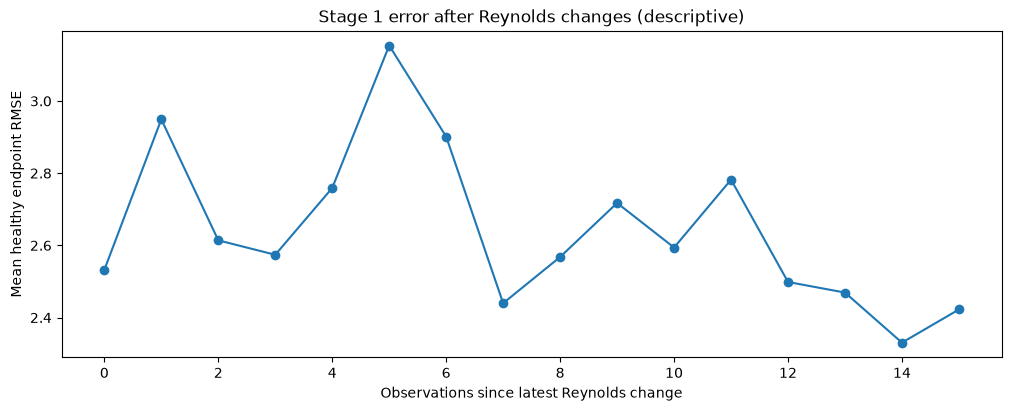

In [23]:
all_change_ix = np.flatnonzero(change)
endpoint_ix = tracking.observation_index.to_numpy() - 1
last_change = np.searchsorted(all_change_ix, endpoint_ix, side="right") - 1
since_change = np.where(last_change>=0, endpoint_ix - all_change_ix[np.maximum(last_change,0)], np.nan)
tracking["steps_since_Re_change"] = since_change
lag_summary = tracking.loc[tracking.steps_since_Re_change.between(0,MAX_LAG)].groupby("steps_since_Re_change").agg(
    n=("endpoint_RMSE","size"), mean_RMSE=("endpoint_RMSE","mean"),
    median_RMSE=("endpoint_RMSE","median"),mean_relative_RMSE=("relative_RMSE","mean"))
display(lag_summary.round(4))
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
ax.plot(lag_summary.index,lag_summary.mean_RMSE,marker="o")
ax.set(xlabel="Observations since latest Reynolds change",ylabel="Mean healthy endpoint RMSE",
       title="Stage 1 error after Reynolds changes (descriptive)")
fig.savefig(OUTPUT_DIR / "rmse_after_reynolds_change.png",dpi=150)
plt.show()

## 8. Save numerical results and a compact diagnostic summary

Outputs are saved in `data/stage1_reynolds_tracking/`. For detailed frequency-level inspection, the long CSV contains **actual**, **predicted**, and **signed residual** for every probe and frequency at every clean healthy endpoint. This may be a large CSV. A compact endpoint CSV and summary tables are also saved.

In [24]:
tracking.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_healthy_stage1_endpoints.csv",index=False)
frequency_metrics.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_frequency_accuracy.csv",index=False)
probe_frequency.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_probe_frequency_transition_accuracy.csv",index=False)
by_re.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_accuracy_by_reynolds.csv")
lag_summary.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_rmse_since_reynolds_change.csv")
# Full wide matrix avoids a huge intermediate 3-column-long table.
wide = tracking[["observation_index", "datetime", "Reynolds"]].copy()
for pi, probe in enumerate(PROBE_ORDER):
    for fi, freq in enumerate(freqs):
        stem = f"{probe}_{freq}"
        wide[f"actual_{stem}"] = actual[:,pi,fi]
        wide[f"predicted_{stem}"] = predicted[:,pi,fi]
        wide[f"residual_{stem}"] = residual[:,pi,fi]
wide.to_csv(OUTPUT_DIR / f"{EXPERIMENT}_actual_predicted_residual_all_channels.csv",index=False)
print("Saved outputs to",OUTPUT_DIR)
print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()): print(" ",p.name)


/tmp/ipykernel_514001/3417791231.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wide[f"predicted_{stem}"] = predicted[:,pi,fi]
/tmp/ipykernel_514001/3417791231.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wide[f"residual_{stem}"] = residual[:,pi,fi]
/tmp/ipykernel_514001/3417791231.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-f

Saved outputs to /home/ubuntu/notebooks/Leak_Detection/results/stage1_reynolds_tracking
Saved files:
  1212_1_accuracy_by_reynolds.csv
  1212_1_actual_predicted_residual_all_channels.csv
  1212_1_frequency_accuracy.csv
  1212_1_healthy_stage1_endpoints.csv
  1212_1_probe_frequency_transition_accuracy.csv
  1212_1_rmse_since_reynolds_change.csv
  error_by_reynolds.png
  probe_frequency_rmse_heatmap.png
  reynolds_vs_stage1_error.png
  rmse_after_reynolds_change.png
  tracking_DDS_f250.png
  tracking_DDS_f31_5.png
  tracking_DDS_f40.png
  tracking_DDS_f50.png
  tracking_DDS_f80.png
  tracking_DS_f250.png
  tracking_DS_f31_5.png
  tracking_DS_f40.png
  tracking_DS_f50.png
  tracking_DS_f80.png
  tracking_US_f250.png
  tracking_US_f31_5.png
  tracking_US_f40.png
  tracking_US_f50.png
  tracking_US_f80.png
  tracking_UUS_f250.png
  tracking_UUS_f31_5.png
  tracking_UUS_f40.png
  tracking_UUS_f50.png
  tracking_UUS_f80.png


## Interpretation guide

- **Actual and predicted spectra closely overlap across Reynolds changes:** Stage 1 is capturing flow effects well for that channel.
- **Systematic residuals at a fixed Reynolds level:** possible baseline bias for that operating regime.
- **Residuals jump when Reynolds changes, then decay:** consistent with transient tracking error or lag; inspect actual/predicted curves to verify.
- **Absolute RMSE increases but relative RMSE stays flat:** possibly amplitude scaling, not necessarily worsening relative prediction quality.
- **Errors concentrated in specific probes/frequencies:** aggregate RMSE can hide important Stage 1 weaknesses.

**Limitations:** This is a single validation experiment, windows overlap, and healthy periods are not independent replicates. The notebook tests Stage 1 accuracy; it does **not** by itself establish that any baseline error causes Stage 2 false positives. That would require aligning these findings with Stage 2 decisions and potentially controlled ablations.